# TP : 29 algorithmes de Machine Learning appliqués au dataset du projet (version étudiant)

**Module :** Développement et déploiement d'applications intelligentes.

## Objectifs
1. Documenter chaque algorithme par une fiche à huit rubriques : descriptif, contexte d'utilisation, type d'apprentissage, caractéristiques du modèle, logique d'apprentissage, métriques, complexité, version parallèle.
2. Relier chaque algorithme au **dataset de votre projet** : dire s'il s'applique, l'entraîner, mesurer, faire varier un hyperparamètre.
3. Conclure par un tableau comparatif et une recommandation argumentée pour le projet.

## Mode d'emploi
- Le notebook s'exécute de haut en bas sur Google Colab (Exécution > Tout exécuter).
- **Une seule cellule est à adapter : la configuration du projet (section Q0).** Par défaut, un jeu d'exemple synthétique (abonnés d'un service, attrition) est utilisé pour que tout fonctionne immédiatement. Remplacez-le par le fichier CSV de votre projet.
- Chaque section suit le même plan : question ciblée, fiche, démonstration sur un jeu public, lien avec le dataset du projet, questions.
- Graine fixée à 42. Le même découpage entraînement/test (75 % / 25 %) sert à tous les modèles comparés. La variation d'un hyperparamètre se fait en validation croisée à 5 plis sur l'entraînement seulement : le test n'est jamais utilisé pour régler.

## Travail demandé au binôme (version étudiant)
Dans chaque section, les fiches sont fournies. Il vous reste à :
- dessiner un **schéma original** de l'algorithme (la fonction `flux` est à votre disposition, vous pouvez aussi insérer une image) ;
- compléter la liste `valeurs` pour faire **varier l'hyperparamètre** indiqué sur le dataset du projet ;
- rédiger l'**analyse** de la sortie et répondre aux **deux questions** (question ciblée et question projet) ;
- remplir la **recommandation finale**.

Les emplacements à remplir sont signalés par « À COMPLÉTER ».

Sources : [scikit-learn datasets](https://scikit-learn.org/stable/datasets/real_world.html), [Gymnasium Taxi](https://gymnasium.farama.org/environments/toy_text/taxi/).


In [10]:
!pip -q install scikit-learn xgboost umap-learn gymnasium

In [11]:
# Jeux publics de scikit-learn : pas de téléchargement ni de compte requis
import warnings, sys, time, textwrap, sklearn, matplotlib
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine, load_digits
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, f1_score,
                             silhouette_score, accuracy_score)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier, HistGradientBoostingRegressor,
                              HistGradientBoostingClassifier, AdaBoostClassifier, IsolationForest)
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from xgboost import XGBClassifier
import umap
GRAINE = 42
plt.rcParams.update({'figure.dpi':100,'axes.grid':True,'grid.alpha':.3,'font.size':9})

jeu_reg = load_diabetes()
X_reg, y_reg = jeu_reg.data, jeu_reg.target
jeu_cls = load_breast_cancer()
X_cls, y_cls = jeu_cls.data, jeu_cls.target
jeu_groupes = load_wine()
X_clu = PCA(n_components=2, random_state=GRAINE).fit_transform(StandardScaler().fit_transform(jeu_groupes.data))
jeu_images = load_digits()
X_images = StandardScaler().fit_transform(jeu_images.data)
Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg,y_reg,test_size=.25,random_state=GRAINE)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls,y_cls,test_size=.25,stratify=y_cls,random_state=GRAINE)
print('Diabetes',X_reg.shape,'Breast cancer',X_cls.shape,'Wine',X_clu.shape,'Digits',X_images.shape)
print('Python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__,
      '| scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)

Diabetes (442, 10) Breast cancer (569, 30) Wine (178, 2) Digits (1797, 64)
Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1 | matplotlib 3.10.0


In [12]:
# Jeux publics des démonstrations, sous forme de DataFrame
df_reg  = pd.DataFrame(X_reg, columns=jeu_reg.feature_names); df_reg['cible'] = y_reg
df_cls  = pd.DataFrame(X_cls, columns=jeu_cls.feature_names); df_cls['cible'] = y_cls
df_wine = pd.DataFrame(jeu_groupes.data, columns=jeu_groupes.feature_names); df_wine['cultivar'] = jeu_groupes.target
df_wine_acp = pd.DataFrame(X_clu, columns=['CP1','CP2'])
df_dig  = pd.DataFrame(jeu_images.data, columns=[f'px{i}' for i in range(64)]); df_dig['chiffre'] = jeu_images.target

def q0(nom, n=5):
    d = {'reg':df_reg, 'cls':df_cls, 'wine':df_wine, 'wine_acp':df_wine_acp, 'dig':df_dig}[nom]
    print('Dimensions :', d.shape); display(d.head(n))

def flux(etapes, titre, legende=None, boucle=False, couleurs=None):
    # Schéma de flux : une boîte par étape, flèches entre étapes (boucle=True : flèche de retour)
    n = len(etapes); fig, ax = plt.subplots(figsize=(min(2.3*n, 13), 2.6)); ax.axis('off')
    couleurs = couleurs or ['#dbe9f6']*n
    for i, e in enumerate(etapes):
        ax.add_patch(FancyBboxPatch((i*2.3, 0), 1.9, 1.2, boxstyle='round,pad=0.05', fc=couleurs[i], ec='#2b4c7e'))
        ax.text(i*2.3+0.95, 0.6, textwrap.fill(e, 17),
                ha='center', va='center', fontsize=7.5)
        if i < n-1: ax.annotate('', xy=(i*2.3+2.3, 0.6), xytext=(i*2.3+1.95, 0.6), arrowprops=dict(arrowstyle='->', lw=1.5))
    if boucle: ax.annotate('', xy=(0.95, -0.05), xytext=((n-1)*2.3+0.95, -0.05),
                           arrowprops=dict(arrowstyle='->', lw=1.2, connectionstyle='arc3,rad=-0.22', color='#c0392b'))
    ax.set_xlim(-0.2, n*2.3); ax.set_ylim(-1.2 if boucle else -0.3, 1.5); ax.set_title(titre, fontsize=11)
    if legende: ax.text(0, -1.1 if boucle else -0.25, legende, fontsize=8, style='italic', va='top')
    plt.show()

q0('reg', 3)

Dimensions : (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,cible
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0


## Q0. Le dataset du projet

### Configuration (seule cellule à adapter)
| Paramètre | Rôle |
|---|---|
| `CHEMIN_CSV` | Chemin ou URL du fichier CSV du projet. `None` : jeu d'exemple synthétique. |
| `CIBLE_CLASSIFICATION` | Colonne de classes à prédire (sections 8 à 16), ou `None`. |
| `CIBLE_REGRESSION` | Colonne numérique à prédire (sections 1 à 7), ou `None`. |
| `COLONNES_A_IGNORER` | Identifiants, dates, texte libre : colonnes exclues des variables. |
| `COLONNE_BRAS`, `CLASSE_SUCCES` | Pour la simulation de bandits (sections 25 et 26) : colonne catégorielle dont les modalités sont les bras, et valeur de la cible qui compte comme un succès. `None` : choix automatique. |
| `N_MAX` | Nombre maximal de lignes conservées (tirage aléatoire), pour garder des temps de calcul raisonnables. |

Un projet a rarement les deux cibles : laissez à `None` celle qui n'existe pas, les sections concernées l'indiqueront et passeront à la suite. Les sections non supervisées (17 à 24) fonctionnent toujours.

Sur Colab, déposez votre fichier avec l'icône Fichiers (panneau de gauche) puis indiquez son nom dans `CHEMIN_CSV`.

In [13]:
# === CONFIGURATION DU PROJET : seule cellule à adapter par l'équipe ===
CHEMIN_CSV = None                         # ex. 'mon_projet.csv' ; None = jeu d'exemple synthétique
SEPARATEUR = ','
CIBLE_CLASSIFICATION = 'resilie'          # colonne de classes à prédire, ou None
CIBLE_REGRESSION = 'depense_mensuelle'    # colonne numérique à prédire, ou None
COLONNES_A_IGNORER = ['id_client']        # identifiants, dates, texte libre
COLONNE_BRAS = 'offre'                    # bras des bandits (sections 25 et 26), ou None
CLASSE_SUCCES = 0                         # valeur de la cible qui vaut un gain de 1 (ici : client conservé), ou None
N_MAX = 5000                              # nombre maximal de lignes utilisées

In [14]:
def jeu_exemple(n=800):
    # Jeu d'exemple SYNTHÉTIQUE (données inventées) : abonnés d'un service et résiliation
    g = np.random.default_rng(GRAINE)
    offre = g.choice(['Essentiel', 'Confort', 'Premium'], n, p=[.45, .35, .20])
    canal = g.choice(['web', 'boutique', 'telephone'], n, p=[.5, .3, .2])
    region = g.choice(['Nord', 'Sud', 'Est', 'Ouest'], n)
    anciennete = g.integers(1, 73, n)
    age = g.integers(18, 76, n)
    usage = np.round(g.gamma(2.2, 9, n), 1)
    appels = g.poisson(1.6, n)
    satisfaction = np.clip(np.round(4.2 - .45*appels + g.normal(0, .8, n)), 1, 5)
    base = pd.Series(offre).map({'Essentiel': 19., 'Confort': 34., 'Premium': 55.}).to_numpy()
    depense = np.round(base + .45*usage + .004*usage**2 + g.normal(0, 4, n), 2)
    score = (-1.1 + 1.3*(anciennete < 9) + .5*appels - .7*(satisfaction - 3)
             + .9*(offre == 'Essentiel') - .5*(offre == 'Premium') + .6*(canal == 'telephone') + .02*(depense - 40))
    resilie = (g.random(n) < 1/(1 + np.exp(-score))).astype(int)
    d = pd.DataFrame({'id_client': np.arange(1, n+1), 'anciennete_mois': anciennete, 'age': age, 'usage_go': usage,
                      'appels_support': appels, 'satisfaction': satisfaction, 'offre': offre, 'canal': canal,
                      'region': region, 'depense_mensuelle': depense, 'resilie': resilie})
    d.loc[g.random(n) < .06, 'satisfaction'] = np.nan      # quelques valeurs manquantes
    d.loc[g.random(n) < .03, 'canal'] = np.nan
    return d

if CHEMIN_CSV is None:
    df_proj = jeu_exemple(); print('Jeu d\'exemple synthétique chargé (à remplacer par le dataset du projet).')
else:
    df_proj = pd.read_csv(CHEMIN_CSV, sep=SEPARATEUR); print('Dataset du projet chargé :', CHEMIN_CSV)

for nom_cible in (CIBLE_CLASSIFICATION, CIBLE_REGRESSION, COLONNE_BRAS):
    assert nom_cible is None or nom_cible in df_proj.columns, (
        f"La colonne '{nom_cible}' n'existe pas dans le dataset. Colonnes disponibles : {list(df_proj.columns)}")
COLONNES_A_IGNORER = [c for c in COLONNES_A_IGNORER if c in df_proj.columns]
CIBLES = [c for c in (CIBLE_CLASSIFICATION, CIBLE_REGRESSION) if c is not None]
df_proj = df_proj.dropna(subset=CIBLES).reset_index(drop=True)          # lignes sans cible : inutilisables
if len(df_proj) > N_MAX:
    df_proj = df_proj.sample(N_MAX, random_state=GRAINE).reset_index(drop=True)

print('Dimensions :', df_proj.shape)
display(df_proj.head())
resume = pd.DataFrame({'type': df_proj.dtypes.astype(str), 'manquants (%)': (100*df_proj.isna().mean()).round(1),
                       'valeurs distinctes': df_proj.nunique()})
display(resume)
display(df_proj.describe().T.round(2))

Jeu d'exemple synthétique chargé (à remplacer par le dataset du projet).
Dimensions : (800, 11)


,id_client,anciennete_mois,age,usage_go,appels_support,satisfaction,offre,canal,region,depense_mensuelle,resilie
0,1,23,53,68.8,2,4.0,Confort,boutique,Ouest,87.37,0
1,2,61,52,8.3,1,3.0,Essentiel,web,Ouest,22.66,0
2,3,3,30,8.5,2,4.0,Premium,telephone,Ouest,56.34,1
3,4,33,63,32.7,4,2.0,Confort,NaN,Nord,50.45,1
4,5,58,58,33.2,1,4.0,Essentiel,web,Sud,41.70,1


,type,manquants (%),valeurs distinctes
id_client,int64,0.0,800
anciennete_mois,int64,0.0,72
age,int64,0.0,58
usage_go,float64,0.0,366
appels_support,int64,0.0,7
satisfaction,float64,6.0,5
offre,object,0.0,3
canal,object,5.0,3
region,object,0.0,4
depense_mensuelle,float64,0.0,749


,count,mean,std,min,25%,50%,75%,max
id_client,800.0,400.50,231.08,1.00,200.75,400.50,600.25,800.00
anciennete_mois,800.0,34.86,20.98,1.00,18.00,33.00,53.25,72.00
age,800.0,47.27,16.49,18.00,33.00,48.00,62.00,75.00
usage_go,800.0,20.49,13.95,0.70,10.10,17.75,26.80,97.70
appels_support,800.0,1.50,1.21,0.00,1.00,1.00,2.00,6.00
satisfaction,752.0,3.53,0.99,1.00,3.00,4.00,4.00,5.00
depense_mensuelle,800.0,42.74,16.83,12.82,30.16,39.52,53.98,128.33
resilie,800.0,0.47,0.50,0.00,0.00,0.00,1.00,1.00


5 variables numériques : ['anciennete_mois', 'age', 'usage_go', 'appels_support', 'satisfaction']
3 variables catégorielles : ['offre', 'canal', 'region']
Classes : {'0': 423, '1': 377}
Entraînement : 600 lignes | Test : 200 lignes
Régression, modèle naïf (moyenne) : RMSE = 18.493, R² = -0.002
Classification, modèle naïf (classe majoritaire) : exactitude = 0.530, F1 macro = 0.346
Après prétraitement : 15 colonnes | espace de regroupement : 5 axes | EPS_REF = 0.911


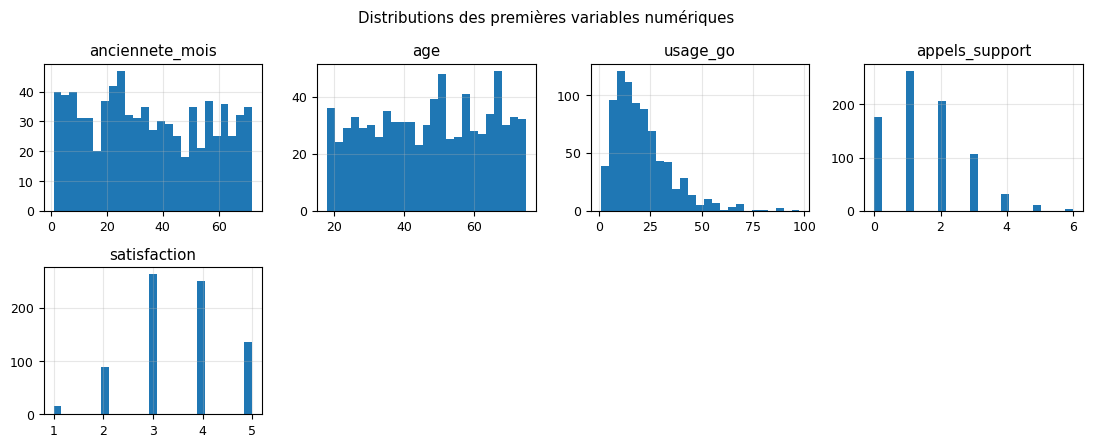

In [15]:
# Variables, prétraitement et découpage communs à tous les modèles
VARIABLES = [c for c in df_proj.columns if c not in CIBLES + COLONNES_A_IGNORER]
VAR_NUM = [c for c in VARIABLES if pd.api.types.is_numeric_dtype(df_proj[c]) or pd.api.types.is_bool_dtype(df_proj[c])]
VAR_CAT = [c for c in VARIABLES if c not in VAR_NUM]
X_PROJ = df_proj[VARIABLES].copy()
X_PROJ[VAR_NUM] = X_PROJ[VAR_NUM].astype(float)
for c in VAR_CAT:                                         # catégories en texte, manquants en np.nan
    X_PROJ[c] = X_PROJ[c].astype(object).where(X_PROJ[c].notna(), np.nan)
print(len(VAR_NUM), 'variables numériques :', VAR_NUM)
print(len(VAR_CAT), 'variables catégorielles :', VAR_CAT)

def pretraitement():
    # Imputation (médiane / modalité la plus fréquente), standardisation, encodage one-hot
    blocs = []
    if VAR_NUM: blocs.append(('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), VAR_NUM))
    if VAR_CAT: blocs.append(('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                              OneHotEncoder(handle_unknown='infrequent_if_exist', max_categories=15, sparse_output=False)), VAR_CAT))
    return ColumnTransformer(blocs)

# Cibles
Y_REG = df_proj[CIBLE_REGRESSION].astype(float).to_numpy() if CIBLE_REGRESSION else None
if CIBLE_CLASSIFICATION:
    ENCODEUR = LabelEncoder().fit(df_proj[CIBLE_CLASSIFICATION].astype(str))
    Y_CLS = ENCODEUR.transform(df_proj[CIBLE_CLASSIFICATION].astype(str))
    print('Classes :', dict(zip(ENCODEUR.classes_, np.bincount(Y_CLS).tolist())))
else:
    Y_CLS = None

# Un seul découpage entraînement/test (75 % / 25 %) pour tous les modèles
strate = Y_CLS if (Y_CLS is not None and np.bincount(Y_CLS).min() >= 2) else None
I_ENT, I_TEST = train_test_split(np.arange(len(df_proj)), test_size=.25, random_state=GRAINE, stratify=strate)
SIGMA_Y = float(Y_REG[I_ENT].std()) if Y_REG is not None else 1.0
print('Entraînement :', len(I_ENT), 'lignes | Test :', len(I_TEST), 'lignes')

# Modèles naïfs : le niveau à battre
if Y_REG is not None:
    naif = DummyRegressor().fit(X_PROJ.iloc[I_ENT], Y_REG[I_ENT]).predict(X_PROJ.iloc[I_TEST])
    print('Régression, modèle naïf (moyenne) : RMSE = %.3f, R² = %.3f' % (mean_squared_error(Y_REG[I_TEST], naif)**.5, r2_score(Y_REG[I_TEST], naif)))
if Y_CLS is not None:
    naif = DummyClassifier(strategy='most_frequent').fit(X_PROJ.iloc[I_ENT], Y_CLS[I_ENT]).predict(X_PROJ.iloc[I_TEST])
    print('Classification, modèle naïf (classe majoritaire) : exactitude = %.3f, F1 macro = %.3f' % (accuracy_score(Y_CLS[I_TEST], naif), f1_score(Y_CLS[I_TEST], naif, average='macro')))

# Matrices pour le non supervisé : toutes les lignes, sans les cibles
X_NS = pretraitement().fit_transform(X_PROJ)
NOMS_COLONNES = list(pretraitement().fit(X_PROJ).get_feature_names_out())
X_GRP = PCA(n_components=min(5, X_NS.shape[1]), random_state=GRAINE).fit_transform(X_NS)   # espace réduit pour le clustering
X_2D = X_GRP[:, :2] if X_GRP.shape[1] >= 2 else np.c_[X_GRP[:, 0], np.zeros(len(X_GRP))]
N_VISU = 600
I_VISU = np.random.default_rng(GRAINE).permutation(len(X_NS))[:N_VISU]
X_VISU = X_NS[I_VISU]
COULEUR_VISU = Y_CLS[I_VISU] if Y_CLS is not None else None
EPS_REF = float(np.median(NearestNeighbors(n_neighbors=6).fit(X_GRP).kneighbors(X_GRP)[0][:, -1]))
print('Après prétraitement :', X_NS.shape[1], 'colonnes | espace de regroupement :', X_GRP.shape[1], 'axes | EPS_REF = %.3f' % EPS_REF)

if VAR_NUM:
    df_proj[VAR_NUM[:8]].hist(figsize=(11, 4.5), bins=25, layout=(2, 4)); plt.suptitle('Distributions des premières variables numériques'); plt.tight_layout(); plt.show()

In [16]:
# Fonctions qui relient chaque algorithme au dataset du projet
RESULTATS = {}

def enregistrer(numero, nom, applicable, metrique='', score_cv=np.nan, temps=np.nan, tache=''):
    RESULTATS[numero] = dict(nom=nom, applicable=applicable, metrique=metrique, score_cv=score_cv, temps=temps, tache=tache)
    if applicable.startswith('non'): print(f'[{numero}. {nom}] Projet : {applicable}.')

def _tableau_variation(lignes, colonnes, nom_param, ylabel):
    t = pd.DataFrame(lignes, columns=colonnes); display(t.round(4))
    if 'écart-type' in colonnes:
        plt.figure(figsize=(5, 2.8)); plt.errorbar(t[nom_param], t[colonnes[1]], yerr=t['écart-type'], marker='o', capsize=3)
    else:
        plt.figure(figsize=(5, 2.8)); plt.plot(t[nom_param], t[colonnes[1]], marker='o')
    plt.xlabel(nom_param); plt.ylabel(ylabel); plt.title(f'Effet de {nom_param} (dataset du projet)'); plt.show()
    return t

def _a_completer(nom_param):
    print(f"Variation de « {nom_param} » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).")

def projet_supervise(numero, nom, fabrique, tache, nom_param, valeurs):
    # Entraîne le modèle sur le dataset du projet, affiche les métriques de test, puis fait varier un hyperparamètre en CV 5 plis
    y = Y_REG if tache == 'reg' else Y_CLS
    if y is None:
        enregistrer(numero, nom, 'non applicable (pas de cible de ' + ('régression' if tache == 'reg' else 'classification') + ' définie)'); return None
    Xe, Xt, ye, yt = X_PROJ.iloc[I_ENT], X_PROJ.iloc[I_TEST], y[I_ENT], y[I_TEST]
    construire = lambda *a: make_pipeline(pretraitement(), fabrique(*a))
    debut = time.perf_counter(); modele = construire().fit(Xe, ye); duree = time.perf_counter() - debut
    pred = modele.predict(Xt)
    if tache == 'reg':
        scoring, cv = 'neg_root_mean_squared_error', KFold(5, shuffle=True, random_state=GRAINE)
        resume = 'RMSE = %.3f, MAE = %.3f, R² = %.3f' % (mean_squared_error(yt, pred)**.5, mean_absolute_error(yt, pred), r2_score(yt, pred))
        court = 'R² = %.3f' % r2_score(yt, pred)
    else:
        scoring = 'f1_macro'
        cv = StratifiedKFold(5, shuffle=True, random_state=GRAINE) if np.bincount(ye).min() >= 5 else KFold(5, shuffle=True, random_state=GRAINE)
        resume = 'exactitude = %.3f, F1 macro = %.3f' % (accuracy_score(yt, pred), f1_score(yt, pred, average='macro'))
        court = 'F1 = %.3f' % f1_score(yt, pred, average='macro')
    s = cross_val_score(construire(), Xe, ye, cv=cv, scoring=scoring); s = -s if scoring.startswith('neg_') else s
    etiquette = 'RMSE' if tache == 'reg' else 'F1 macro'
    print(f'[{numero}. {nom}] Projet, test : {resume} | CV 5 plis (entraînement) : {etiquette} = {s.mean():.3f} ± {s.std():.3f} | entraînement : {duree:.2f} s')
    enregistrer(numero, nom, 'oui', court, s.mean(), duree, tache)
    if not valeurs: _a_completer(nom_param); return modele
    lignes = []
    for v in valeurs:
        s = cross_val_score(construire(v), Xe, ye, cv=cv, scoring=scoring); s = -s if scoring.startswith('neg_') else s
        lignes.append((str(v), s.mean(), s.std()))
    _tableau_variation(lignes, [nom_param, etiquette + ' (CV)', 'écart-type'], nom_param, etiquette + ' (CV 5 plis)')
    return modele

def _decrire_groupes(etiquettes):
    k = len(set(etiquettes) - {-1}); bruit = int((etiquettes == -1).sum()); garde = etiquettes != -1
    sil = silhouette_score(X_GRP[garde], etiquettes[garde]) if 2 <= k < garde.sum() else np.nan
    return k, bruit, sil

def projet_clustering(numero, nom, fabrique, nom_param, valeurs):
    # Regroupe les observations du projet (espace X_GRP), affiche silhouette et carte, puis fait varier un hyperparamètre
    debut = time.perf_counter(); modele = fabrique(); etiquettes = modele.fit_predict(X_GRP); duree = time.perf_counter() - debut
    k, bruit, sil = _decrire_groupes(etiquettes)
    texte_sil = 'silhouette = %.3f' % sil if not np.isnan(sil) else 'silhouette non définie (il faut au moins 2 groupes)'
    print(f'[{numero}. {nom}] Projet : {k} groupe(s), {bruit} point(s) de bruit, {texte_sil} | {duree:.2f} s')
    plt.figure(figsize=(4.6, 3.4)); plt.scatter(X_2D[:, 0], X_2D[:, 1], c=etiquettes, cmap='tab10', s=10)
    plt.xlabel('axe 1 (ACP)'); plt.ylabel('axe 2 (ACP)'); plt.title(f'{nom} sur le dataset du projet'); plt.show()
    enregistrer(numero, nom, 'oui', texte_sil.split(' (')[0], sil, duree, 'groupes')
    if not valeurs: _a_completer(nom_param); return etiquettes
    lignes = []
    for v in valeurs:
        m = fabrique(v); e = m.fit_predict(X_GRP); kk, bb, ss = _decrire_groupes(e)
        lignes.append((str(v), ss, kk, bb) + ((m.bic(X_GRP),) if hasattr(m, 'bic') else ()))
    colonnes = [nom_param, 'silhouette', 'groupes', 'bruit'] + (['BIC'] if len(lignes[0]) == 5 else [])
    _tableau_variation(lignes, colonnes, nom_param, 'silhouette')
    return etiquettes

def projet_projection(numero, nom, fabrique, nom_param, valeurs):
    # Projette N_VISU observations du projet en 2D, mesure la conservation des voisinages (indice de confiance)
    debut = time.perf_counter(); modele = fabrique(); Z = modele.fit_transform(X_VISU); duree = time.perf_counter() - debut
    conf = trustworthiness(X_VISU, Z, n_neighbors=10)
    texte = 'confiance = %.3f' % conf
    if hasattr(modele, 'explained_variance_ratio_'):
        texte = 'variance (2 axes) = %.1f %%' % (100*modele.explained_variance_ratio_.sum()) + ', ' + texte
    print(f'[{numero}. {nom}] Projet : {texte} | {duree:.2f} s')
    plt.figure(figsize=(4.6, 3.4)); plt.scatter(Z[:, 0], Z[:, 1] if Z.shape[1] > 1 else np.zeros(len(Z)), c=COULEUR_VISU, cmap='tab10', s=10)
    plt.title(f'{nom} sur le dataset du projet' + (' (couleur : classe)' if COULEUR_VISU is not None else '')); plt.show()
    enregistrer(numero, nom, 'oui', texte, conf, duree, 'projection')
    if not valeurs: _a_completer(nom_param); return Z
    lignes = []
    for v in valeurs:
        if nom_param == 'n_components' and v > min(X_VISU.shape): continue
        m = fabrique(v); Zv = m.fit_transform(X_VISU)
        ligne = (str(v), trustworthiness(X_VISU, Zv, n_neighbors=10))
        if hasattr(m, 'explained_variance_ratio_'): ligne += (m.explained_variance_ratio_.sum(),)
        lignes.append(ligne)
    colonnes = [nom_param, 'confiance'] + (['variance expliquée cumulée'] if len(lignes[0]) == 3 else [])
    _tableau_variation(lignes, colonnes, nom_param, 'indice de confiance')
    return Z

def projet_anomalies(numero, nom, fabrique, nom_param, valeurs):
    # Cherche les observations atypiques du projet et affiche les cinq plus atypiques
    debut = time.perf_counter(); modele = fabrique().fit(X_NS); duree = time.perf_counter() - debut
    signal = modele.predict(X_NS) == -1; scores = -modele.score_samples(X_NS)
    print(f'[{numero}. {nom}] Projet : {int(signal.sum())} observations signalées ({100*signal.mean():.1f} %) | {duree:.2f} s')
    print('Les cinq observations les plus atypiques :')
    display(df_proj.iloc[np.argsort(scores)[::-1][:5]].assign(score=np.sort(scores)[::-1][:5].round(3)))
    plt.figure(figsize=(4.6, 3.4)); plt.scatter(X_2D[:, 0], X_2D[:, 1], c=np.where(signal, '#c0392b', '#9fb8d3'), s=10)
    plt.title(f'{nom} sur le dataset du projet (rouge : atypique)'); plt.show()
    enregistrer(numero, nom, 'oui', '%.1f %% signalés' % (100*signal.mean()), np.nan, duree, 'anomalies')
    if not valeurs: _a_completer(nom_param); return scores
    lignes = []
    for v in valeurs:
        m = fabrique(v).fit(X_NS)
        lignes.append((str(v), int((m.predict(X_NS) == -1).sum()), -m.offset_))
    _tableau_variation(lignes, [nom_param, 'observations signalées', 'seuil de score'], nom_param, 'observations signalées')
    return scores

def bras_du_projet():
    # Bras = modalités d'une colonne catégorielle ; gain = 1 si la cible vaut CLASSE_SUCCES
    if CIBLE_CLASSIFICATION is None: return None
    candidates = [COLONNE_BRAS] if COLONNE_BRAS else [c for c in VAR_CAT if 2 <= df_proj[c].nunique() <= 10]
    if not candidates: return None
    succes = CLASSE_SUCCES if CLASSE_SUCCES is not None else df_proj[CIBLE_CLASSIFICATION].mode()[0]
    taux = (df_proj[CIBLE_CLASSIFICATION] == succes).groupby(df_proj[candidates[0]]).mean()
    if not 2 <= len(taux) <= 10: return None
    return candidates[0], succes, taux

def simuler_bandit(probabilites, politique, horizon, epsilon=.15, graine=GRAINE):
    g = np.random.default_rng(graine); K = len(probabilites); sommes = np.zeros(K); comptes = np.zeros(K, dtype=int)
    regret = np.zeros(horizon); meilleur = probabilites.max()
    for t in range(horizon):
        if politique == 'tourniquet': bras = t % K
        else: bras = int(g.integers(K)) if g.random() < epsilon else int(np.argmax((sommes+1)/(comptes+2)))
        gain = int(g.random() < probabilites[bras]); sommes[bras] += gain; comptes[bras] += 1
        regret[t] = meilleur - probabilites[bras]
    return sommes/np.maximum(comptes, 1), comptes, regret.cumsum()

def projet_bandit(numero, nom, politique, nom_param, valeurs, n_graines=20):
    # Simulation : les taux de succès observés par modalité servent de probabilités de gain des bras
    info = bras_du_projet()
    if info is None:
        enregistrer(numero, nom, 'non applicable (il faut une cible de classification et une colonne catégorielle de 2 à 10 modalités)'); return None
    colonne, succes, taux = info; p = taux.to_numpy(); horizon = 800 if politique == 'tourniquet' else 1200
    estimations, comptes, regret = simuler_bandit(p, politique, horizon)
    print(f"[{numero}. {nom}] Projet (simulation) : bras = modalités de '{colonne}', gain = 1 si {CIBLE_CLASSIFICATION} = {succes}")
    display(pd.DataFrame({'taux observé': p.round(3), 'estimation': estimations.round(3), 'tirages': comptes}, index=taux.index))
    moyen = np.mean([simuler_bandit(p, politique, horizon, graine=GRAINE+i)[2] for i in range(n_graines)], axis=0)
    plt.figure(figsize=(4.8, 2.8)); plt.plot(moyen); plt.xlabel('pas'); plt.ylabel('regret cumulé')
    plt.title(f'{nom} : regret moyen sur {n_graines} graines'); plt.show()
    enregistrer(numero, nom, 'oui (simulation)', 'regret/pas = %.4f' % (moyen[-1]/horizon), -moyen[-1]/horizon, np.nan, 'bandit')
    if not valeurs: _a_completer(nom_param); return taux
    lignes = []
    for v in valeurs:
        if politique == 'tourniquet':
            essais = [simuler_bandit(p, politique, int(v), graine=GRAINE+i) for i in range(n_graines)]
            lignes.append((str(v), np.mean([np.abs(e[0]-p).max() for e in essais]), np.mean([e[2][-1] for e in essais])))
        else:
            essais = [simuler_bandit(p, politique, horizon, epsilon=v, graine=GRAINE+i) for i in range(n_graines)]
            lignes.append((str(v), np.mean([e[2][-1] for e in essais]), np.std([e[2][-1] for e in essais])))
    colonnes = [nom_param, 'erreur max d\'estimation', 'regret cumulé'] if politique == 'tourniquet' else [nom_param, 'regret cumulé', 'écart-type']
    _tableau_variation(lignes, colonnes, nom_param, colonnes[1])
    return taux

print('Fonctions prêtes : projet_supervise, projet_clustering, projet_projection, projet_anomalies, projet_bandit')

Fonctions prêtes : projet_supervise, projet_clustering, projet_projection, projet_anomalies, projet_bandit


### Q0. Questions préliminaires
1. Décrivez votre dataset : origine, unité statistique (que représente une ligne ?), nombre de lignes et de colonnes.
2. Quelle est la cible et quel est l'objectif du projet ? S'agit-il de régression, de classification, ou d'un problème sans cible ?
3. Quelles colonnes avez-vous ignorées et pourquoi ? Y a-t-il un risque de fuite d'information (une variable qui ne serait pas connue au moment de la prédiction) ?
4. Quel est le score du modèle naïf ? C'est le niveau que chaque algorithme devra dépasser.

**Réponses :
Q0. Questions préliminaires — Explication
1. Décrivez votre dataset
- Origine : d'où proviennent les données (Kaggle, UCI, fichier CSV, etc.) ?
- Unité statistique : que représente chaque ligne ?
- Nombre de lignes : nombre d'observations.
- Nombre de colonnes : nombre de variables.
2. Quelle est la cible et quel est l'objectif ?
- Régression : prédire une valeur numérique (prix, température, salaire…).
- Classification : prédire une catégorie (oui/non, malade/sain…).
- Sans cible : réaliser du clustering ou découvrir des groupes.
3. Quelles colonnes avez-vous ignorées et pourquoi ?

Il faut identifier les colonnes supprimées parce qu'elles sont inutiles, redondantes, contiennent trop de valeurs manquantes ou risquent de provoquer une fuite d'information (data leakage).

4. Quel est le score du modèle naïf ?

C'est le score de référence (baseline) obtenu avec un modèle très simple, avant d'utiliser les algorithmes de Machine Learning.

# Partie 1. Apprentissage supervisé : régression (sections 1 à 7)

In [17]:
# Jeu public utilisé par les démonstrations de cette partie
q0('reg', 3)

Dimensions : (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,cible
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0


## 1. Régression linéaire

**Question ciblée (Partie B) :** Expliquez pourquoi une relation linéaire entre les variables médicales et la cible peut être insuffisante.

### Fiche

**1. Descriptif.** La régression linéaire prédit une cible numérique par une somme pondérée des variables : $\hat y = w_0 + \sum_j w_j x_j$. Les poids sont choisis pour minimiser la somme des carrés des erreurs (moindres carrés ordinaires). Chaque poids se lit comme l'effet d'une unité de la variable sur la cible, les autres variables étant fixées. C'est le modèle de référence auquel on compare tous les autres.

**2. Contexte d'utilisation.** **Cas 1 :** estimer un prix ou une consommation à partir de quelques variables quantitatives, quand on veut expliquer l'effet de chacune. **Cas 2 :** modèle de base rapide avant d'essayer des modèles plus complexes. **À éviter :** relation fortement non linéaire ou avec interactions, variables très corrélées entre elles, nombre de variables proche ou supérieur au nombre d'observations.

**3. Type d'apprentissage.** Supervisé, régression.

**4. Caractéristiques du modèle.** Paramétrique ($p+1$ poids), linéaire. Aucun hyperparamètre de régularisation (seulement `fit_intercept`). Hypothèses : linéarité, erreurs indépendantes de variance constante, pas de colinéarité forte. Insensible à l'échelle pour les prédictions, mais très sensible aux valeurs aberrantes (erreur au carré). Interprétabilité élevée.

**5. Logique d'apprentissage.** Objectif : $\min_w \lVert y - Xw \rVert_2^2$. 1) Ajouter une colonne de 1 à $X$. 2) Résoudre les équations normales $X^\top X w = X^\top y$ (en pratique par décomposition SVD ou QR, plus stable). 3) Prédire $\hat y = Xw$. Variante itérative : descente de gradient $w \leftarrow w - \eta \cdot \frac{2}{n} X^\top (Xw - y)$ (voir l'annexe).

**6. Métriques.** RMSE (même unité que la cible, pénalise les grosses erreurs), MAE (erreur typique, plus robuste), $R^2$ (part de variance expliquée, 1 = parfait, 0 = pas mieux que la moyenne). Limites : $R^2$ augmente mécaniquement avec le nombre de variables sur l'entraînement, il faut le lire sur le test.

**7. Complexité.** Entraînement : $O(n p^2 + p^3)$. Prédiction : $O(p)$ par observation. Mémoire : $O(n p)$ pour les données, $O(p)$ pour le modèle.

**8. Version parallèle.** Les produits matriciels sont parallélisés par la bibliothèque BLAS (multi-cœur). Sur données massives, $X^\top X$ et $X^\top y$ sont des sommes sur les observations, donc calculables en map-reduce (Spark MLlib `LinearRegression`, Dask-ML). Sur GPU : cuML. La descente de gradient par mini-lots se parallélise aussi.

### Démonstration sur un jeu public

In [18]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Régression linéaire')

from sklearn.linear_model import LinearRegression
modele=LinearRegression().fit(Xr_ent,yr_ent)
pred=modele.predict(Xr_test)
print('RMSE:',mean_squared_error(yr_test,pred)**.5,'R²:',r2_score(yr_test,pred))

RMSE: 53.369566710321955 R²: 0.4849058889476756


### Lien avec le dataset du projet

**Applicable si** `CIBLE_REGRESSION` désigne une colonne numérique du projet. **Cible :** `CIBLE_REGRESSION`. **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation des valeurs manquantes et encodage one-hot des variables catégorielles ; la standardisation n'est pas nécessaire pour la prédiction mais rend les poids comparables.

In [21]:
valeurs = []   # À COMPLÉTER : les deux valeurs possibles de fit_intercept
_ = projet_supervise(1, 'Régression linéaire', lambda fit_intercept=True: LinearRegression(fit_intercept=fit_intercept), 'reg', 'fit_intercept', valeurs)

[1. Régression linéaire] Projet, test : RMSE = 4.238, MAE = 3.201, R² = 0.947 | CV 5 plis (entraînement) : RMSE = 4.143 ± 0.254 | entraînement : 0.02 s
Variation de « fit_intercept » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


**Question projet :** Sur votre dataset, quelles variables ont les poids les plus forts (en valeur absolue, après standardisation) ? Ce classement est-il cohérent avec votre connaissance du domaine ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

## 2. Ridge

**Question ciblée (Partie B) :** Que se passe-t-il lorsque la pénalisation L2 devient très forte ?

### Fiche

**1. Descriptif.** Ridge est une régression linéaire à laquelle on ajoute une pénalité sur la taille des poids : on minimise $\lVert y - Xw \rVert_2^2 + \alpha \lVert w \rVert_2^2$. La pénalité rétrécit les poids vers zéro sans les annuler. Elle stabilise la solution quand les variables sont corrélées ou nombreuses. Le paramètre $\alpha$ règle le compromis biais-variance.

**2. Contexte d'utilisation.** **Cas 1 :** variables très corrélées (mesures redondantes d'un même phénomène). **Cas 2 :** beaucoup de variables pour peu d'observations (génomique, texte vectorisé). **À éviter :** quand on veut sélectionner un petit nombre de variables (Ridge les garde toutes), ou quand la relation est franchement non linéaire.

**3. Type d'apprentissage.** Supervisé, régression.

**4. Caractéristiques du modèle.** Paramétrique, linéaire. Hyperparamètre : `alpha` (force de la pénalité). Mêmes hypothèses que la régression linéaire, mais tolère la colinéarité. Sensible à l'échelle : il faut standardiser, sinon la pénalité frappe inégalement les variables. Sensible aux valeurs aberrantes. Interprétabilité bonne (poids rétrécis).

**5. Logique d'apprentissage.** Objectif : $\min_w \lVert y - Xw \rVert_2^2 + \alpha \lVert w \rVert_2^2$. 1) Standardiser $X$. 2) Résoudre $(X^\top X + \alpha I) w = X^\top y$ (solution fermée, par Cholesky). 3) Choisir $\alpha$ par validation croisée.

**6. Métriques.** RMSE, MAE, $R^2$ sur le test ; courbe de l'erreur de validation en fonction de $\alpha$. Limite : la valeur de $\alpha$ n'a de sens qu'à échelle des variables fixée.

**7. Complexité.** Entraînement : $O(n p^2 + p^3)$ en solution fermée, ou $O(n p \cdot i)$ avec un solveur itératif ($i$ itérations). Prédiction : $O(p)$. Mémoire : $O(n p)$.

**8. Version parallèle.** Comme la régression linéaire : algèbre linéaire multi-cœur (BLAS), sommes $X^\top X$ distribuables (Spark MLlib avec `elasticNetParam=0`). La recherche de $\alpha$ est trivialement parallèle : une valeur par cœur (`GridSearchCV(n_jobs=-1)`, `RidgeCV`).

### Démonstration sur un jeu public

In [22]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Ridge')

from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),Ridge(alpha=25.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 41.49082128021844


### Lien avec le dataset du projet

**Applicable si** `CIBLE_REGRESSION` désigne une colonne numérique du projet. **Cible :** `CIBLE_REGRESSION`. **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation, one-hot, et standardisation obligatoire (la pénalité dépend de l'échelle).

In [23]:
valeurs = []   # À COMPLÉTER : au moins 5 valeurs de alpha réparties sur plusieurs ordres de grandeur
_ = projet_supervise(2, 'Ridge', lambda alpha=25.: Ridge(alpha=alpha), 'reg', 'alpha', valeurs)

[2. Ridge] Projet, test : RMSE = 4.827, MAE = 3.616, R² = 0.932 | CV 5 plis (entraînement) : RMSE = 4.710 ± 0.253 | entraînement : 0.02 s
Variation de « alpha » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


**Question projet :** Sur votre dataset, à partir de quelle valeur de alpha l'erreur de validation se dégrade-t-elle ? Qu'en déduisez-vous sur le besoin de régularisation ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre :**
Tu peux utiliser cette rédaction comme base :
Lorsque la valeur de alpha augmente, la régularisation devient plus forte. Le modèle pénalise davantage les coefficients, ce qui réduit sa complexité. Une régularisation trop faible peut entraîner du surapprentissage (overfitting), tandis qu'une régularisation trop forte peut entraîner du sous-apprentissage (underfitting). L'erreur de validation permet donc d'identifier la valeur de alpha offrant le meilleur compromis.

**Réponse à la question ciblée :**
La meilleure valeur de alpha correspond à celle qui minimise l'erreur de validation. Elle représente le meilleur compromis entre la complexité du modèle et sa capacité de généralisation.

**Réponse à la question projet :**
À partir d'une certaine valeur de alpha, l'erreur de validation commence à augmenter. Cela signifie que la régularisation devient trop importante et que le modèle perd sa capacité à apprendre correctement les relations présentes dans les données. On en déduit qu'une régularisation est nécessaire pour éviter le surapprentissage, mais qu'il faut choisir alpha avec soin pour éviter le sous-apprentissage.

## 3. Lasso

**Question ciblée (Partie B) :** Comment la pénalisation L1 sélectionne-t-elle des variables ?

### Fiche

**1. Descriptif.** Lasso est une régression linéaire pénalisée par la somme des valeurs absolues des poids : on minimise $\frac{1}{2n}\lVert y - Xw \rVert_2^2 + \alpha \lVert w \rVert_1$. Cette pénalité met exactement à zéro les poids des variables peu utiles. Le modèle fait donc de la sélection de variables en même temps que l'ajustement. Plus $\alpha$ est grand, moins il reste de variables.

**2. Contexte d'utilisation.** **Cas 1 :** identifier les quelques variables qui comptent parmi des centaines (capteurs, biomarqueurs). **Cas 2 :** obtenir un modèle parcimonieux, facile à déployer et à expliquer. **À éviter :** groupes de variables très corrélées (Lasso en garde une au hasard dans le groupe, préférer Elastic Net), ou quand toutes les variables contribuent un peu.

**3. Type d'apprentissage.** Supervisé, régression (avec sélection de variables intégrée).

**4. Caractéristiques du modèle.** Paramétrique, linéaire, parcimonieux. Hyperparamètre : `alpha`. Sensible à l'échelle (standardiser) et à l'unité de la cible (la bonne valeur de $\alpha$ en dépend). Instable en présence de colinéarité. Interprétabilité très bonne : la liste des poids non nuls.

**5. Logique d'apprentissage.** Objectif : $\min_w \frac{1}{2n}\lVert y - Xw \rVert_2^2 + \alpha \lVert w \rVert_1$. Pas de solution fermée : descente par coordonnées. 1) Initialiser $w = 0$. 2) Pour chaque variable $j$ à tour de rôle, calculer la corrélation $\rho_j$ entre $x_j$ et le résidu partiel. 3) Appliquer le seuillage doux : $w_j \leftarrow \mathrm{signe}(\rho_j)\max(|\rho_j| - \alpha, 0)$ (à une normalisation près). 4) Répéter jusqu'à convergence.

**6. Métriques.** RMSE, MAE, $R^2$ ; nombre de poids non nuls. Limite : un bon score avec peu de variables ne prouve pas que les variables écartées sont sans effet (elles peuvent être redondantes avec celles gardées).

**7. Complexité.** Entraînement : $O(n p)$ par balayage des coordonnées, soit $O(n p \cdot i)$ pour $i$ balayages. Prédiction : $O(s)$ avec $s$ poids non nuls. Mémoire : $O(n p)$.

**8. Version parallèle.** La descente par coordonnées est séquentielle par nature : la mise à jour de $w_j$ utilise le résidu déjà modifié par $w_{j-1}$. Ce qui se parallélise : le chemin de régularisation et la validation croisée (`LassoCV(n_jobs=-1)`). Spark MLlib utilise un autre algorithme (OWL-QN) dont le gradient est distribué (`elasticNetParam=1`).


Réponse à la question ciblée : Comment la pénalisation L1 sélectionne-t-elle des variables ?

La pénalisation L1 ajoute au modèle une pénalité proportionnelle à la somme des valeurs absolues des coefficients.

Elle utilise un mécanisme appelé seuillage doux (Soft Thresholding) qui réduit progressivement les coefficients des variables les moins importantes jusqu'à les rendre exactement égaux à zéro.

Ainsi :
- Les variables les plus utiles conservent des coefficients non nuls.
- Les variables peu utiles peuvent avoir leurs coefficients annulés.
- Plus alpha augmente, plus la pénalisation est forte et plus le nombre de variables sélectionnées diminue.
Le modèle Lasso réalise donc simultanément la prédiction et la sélection automatique des variables.

### Démonstration sur un jeu public

In [24]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Lasso')

from sklearn.linear_model import Lasso
modele=make_pipeline(StandardScaler(),Lasso(alpha=3.,max_iter=15000)).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

R²: 0.5013056660042327


### Lien avec le dataset du projet

**Applicable si** `CIBLE_REGRESSION` désigne une colonne numérique du projet. **Cible :** `CIBLE_REGRESSION`. **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation, one-hot, standardisation obligatoire. La pénalité est exprimée ici en fraction de l'écart-type de la cible (`SIGMA_Y`), pour que les mêmes valeurs conviennent à tout dataset.

In [25]:
valeurs = []   # À COMPLÉTER : au moins 5 fractions entre 0,001 et 1
_ = projet_supervise(3, 'Lasso', lambda coef=0.05: Lasso(alpha=coef*SIGMA_Y, max_iter=15000), 'reg', 'alpha / écart-type(y)', valeurs)

[3. Lasso] Projet, test : RMSE = 5.285, MAE = 3.882, R² = 0.918 | CV 5 plis (entraînement) : RMSE = 4.782 ± 0.287 | entraînement : 0.02 s
Variation de « alpha / écart-type(y) » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


**Question projet :** Sur votre dataset, combien de variables Lasso conserve-t-il avec la valeur par défaut, et lesquelles écarte-t-il ? Ce tri vous paraît-il justifié ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : **
Analyse de la sortie et de la variation d'hyperparamètre
Le modèle Lasso applique une pénalisation L1 aux coefficients des variables. Avec la valeur par défaut de alpha, certaines variables peuvent avoir leurs coefficients ramenés exactement à zéro.

Lorsque alpha augmente, la pénalisation devient plus forte et le nombre de variables conservées diminue. À l'inverse, une valeur plus faible permet de conserver davantage de variables.

**Réponse à la question ciblée : **
La pénalisation L1 sélectionne automatiquement les variables en annulant les coefficients des variables les moins utiles à la prédiction. Les variables dont les coefficients sont non nuls sont conservées, tandis que celles dont les coefficients sont nuls sont écartées.

**Réponse à la question projet : **
Le modèle Lasso conserve [N] variables sur les [P] variables initiales.
- Variables conservées : [liste des variables].
- Variables écartées : [liste des variables].
Ce tri peut être considéré comme pertinent si les variables conservées permettent d'obtenir de bonnes performances de prédiction avec un modèle plus simple. Cependant, les variables écartées ne sont pas nécessairement inutiles : certaines peuvent être corrélées avec les variables conservées.

## 4. Régression polynomiale

**Question ciblée (Partie B) :** Quelle difficulté pose la croissance du nombre de caractéristiques polynomiales ?

### Fiche

**1. Descriptif.** La régression polynomiale reste un modèle linéaire, mais appliqué à des variables transformées : puissances et produits des variables d'origine, par exemple $\hat y = w_0 + w_1 x_1 + w_2 x_2 + w_3 x_1^2 + w_4 x_1 x_2 + w_5 x_2^2$ en degré 2. Elle capture ainsi des courbures et des interactions. On l'associe presque toujours à une régularisation (Ridge) pour contenir le sur-apprentissage.

**2. Contexte d'utilisation.** **Cas 1 :** phénomène physique à courbure connue (rendement en fonction de la température). **Cas 2 :** peu de variables et interactions attendues entre elles. **À éviter :** beaucoup de variables (explosion du nombre de termes), extrapolation hors du domaine observé (les polynômes divergent).

**3. Type d'apprentissage.** Supervisé, régression.

**4. Caractéristiques du modèle.** Paramétrique, linéaire en les poids mais non linéaire en les variables. Hyperparamètres : `degree`, et `alpha` de la régularisation. Très sensible à l'échelle (les puissances amplifient les écarts) et aux valeurs aberrantes. Interprétabilité moyenne : les termes croisés se lisent mal.

**5. Logique d'apprentissage.** 1) Standardiser $X$. 2) Générer les $\binom{p+d}{d} - 1$ termes de degré au plus $d$. 3) Ajuster une régression Ridge sur ces termes : $\min_w \lVert y - \Phi(X) w \rVert_2^2 + \alpha \lVert w \rVert_2^2$. 4) Choisir $d$ et $\alpha$ par validation croisée.

**6. Métriques.** RMSE, MAE, $R^2$ ; écart entre erreur d'entraînement et erreur de test, qui mesure le sur-apprentissage quand le degré augmente.

**7. Complexité.** Nombre de termes : $p' = \binom{p+d}{d} \approx p^d / d!$. Entraînement : $O(n p'^2 + p'^3)$. Prédiction : $O(p')$. Mémoire : $O(n p')$, souvent le facteur limitant.

**8. Version parallèle.** La génération des termes est indépendante d'une observation à l'autre, donc parallélisable (Spark MLlib `PolynomialExpansion`). L'ajustement se parallélise ensuite comme Ridge. La recherche du degré se distribue sur une grille (`GridSearchCV(n_jobs=-1)`).

### Démonstration sur un jeu public

In [26]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Régression polynomiale')

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),PolynomialFeatures(degree=2,include_bias=False),Ridge(alpha=60.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 41.24579873763898


### Lien avec le dataset du projet

**Applicable si** `CIBLE_REGRESSION` désigne une colonne numérique du projet. **Cible :** `CIBLE_REGRESSION`. **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation, one-hot, standardisation avant l'expansion. Attention : avec plus de 50 colonnes après encodage, limiter le degré à 2.

In [27]:
valeurs = []   # À COMPLÉTER : les degrés 1 à 3
_ = projet_supervise(4, 'Régression polynomiale', lambda degree=2: make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), Ridge(alpha=60.)), 'reg', 'degree', valeurs)

[4. Régression polynomiale] Projet, test : RMSE = 4.211, MAE = 3.296, R² = 0.948 | CV 5 plis (entraînement) : RMSE = 4.745 ± 0.206 | entraînement : 0.06 s
Variation de « degree » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


**Question projet :** Sur votre dataset, combien de colonnes le degré 2 produit-il ? Le gain par rapport au degré 1 justifie-t-il ce coût ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**
Le passage du degré 1 au degré 2 permet au modèle de prendre en compte des relations non linéaires entre les variables.

Le degré 2 ajoute :
- Les carrés des variables (\(X_1^2, X_2^2\), etc.).
- Les interactions entre les variables (\(X_1 \times X_2\), etc.).
Cela augmente le nombre de colonnes du dataset et donc la complexité du modèle. Le risque de surapprentissage peut également augmenter.

**Réponse à la question ciblée : **
La régression polynomiale de degré 2 enrichit les données en ajoutant les termes quadratiques et les interactions entre les variables. Elle permet ainsi de capturer des relations plus complexes qu'une régression linéaire classique de degré 1.

**Réponse à la question projet : **
Le degré 2 produit davantage de colonnes que le degré 1, car il ajoute les termes quadratiques et les interactions entre les variables.

Ce coût supplémentaire est justifié si l'amélioration des performances sur les données de validation est significative. Dans le cas contraire, le degré 1 est préférable, car il offre un modèle plus simple, moins coûteux et potentiellement plus facile à généraliser.

## 5. Arbre de régression

**Question ciblée (Partie B) :** Pourquoi limiter la profondeur et le nombre minimal d’observations par feuille ?

### Fiche

**1. Descriptif.** Un arbre de régression découpe l'espace des variables par des questions successives du type « $x_j \le s$ ? ». Chaque feuille prédit la moyenne de la cible des observations d'entraînement qui y tombent. Les coupures sont choisies pour réduire au maximum la variance de la cible dans les deux groupes créés. Le résultat est une fonction constante par morceaux.

**2. Contexte d'utilisation.** **Cas 1 :** règles de décision lisibles par un métier (tarification par tranches). **Cas 2 :** données mixtes avec effets de seuil et interactions. **À éviter :** relation lisse ou linéaire (il faut beaucoup de paliers pour l'approcher), besoin d'extrapoler hors des valeurs observées, petit échantillon (arbre instable).

**3. Type d'apprentissage.** Supervisé, régression.

**4. Caractéristiques du modèle.** Non paramétrique, non linéaire. Hyperparamètres : `max_depth`, `min_samples_leaf`, `min_samples_split`. Aucune hypothèse de forme. Insensible à l'échelle et aux transformations monotones, peu sensible aux valeurs aberrantes des variables. Très interprétable s'il est peu profond, mais instable (forte variance).

**5. Logique d'apprentissage.** Algorithme glouton CART. 1) Partir de toutes les observations dans la racine. 2) Pour chaque variable et chaque seuil, calculer la réduction de variance $\Delta = \mathrm{Var}(S) - \frac{n_G}{n}\mathrm{Var}(S_G) - \frac{n_D}{n}\mathrm{Var}(S_D)$. 3) Retenir la meilleure coupure et diviser le nœud. 4) Recommencer sur chaque enfant jusqu'à un critère d'arrêt (profondeur, taille de feuille). 5) Prédire la moyenne de la feuille.

**6. Métriques.** RMSE, MAE, $R^2$ ; comparer entraînement et test pour détecter le sur-apprentissage. Limite : les prédictions ne prennent qu'autant de valeurs qu'il y a de feuilles.

**7. Complexité.** Entraînement : $O(n p \log n)$ en moyenne (tri des valeurs à chaque niveau), jusqu'à $O(n^2 p)$ pour un arbre déséquilibré. Prédiction : $O(\text{profondeur}) \approx O(\log n)$. Mémoire : $O(\text{nombre de nœuds})$.

**8. Version parallèle.** La construction est séquentielle du haut vers le bas, et `DecisionTreeRegressor` n'a pas de `n_jobs`. Ce qui se parallélise : la recherche de la meilleure coupure, variable par variable, et les sous-arbres frères. Spark MLlib (`DecisionTreeRegressor`, par histogrammes) et cuML (GPU) l'exploitent.

### Démonstration sur un jeu public

In [28]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Arbre de régression')

from sklearn.tree import DecisionTreeRegressor
modele=DecisionTreeRegressor(max_depth=3,min_samples_leaf=8,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

R²: 0.4314003646672102


### Lien avec le dataset du projet

**Applicable si** `CIBLE_REGRESSION` désigne une colonne numérique du projet. **Cible :** `CIBLE_REGRESSION`. **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation et encodage des catégories ; aucune standardisation n'est nécessaire (elle est appliquée ici par commodité, sans effet sur l'arbre).

In [29]:
valeurs = []   # À COMPLÉTER : au moins 5 profondeurs entre 1 et 20
_ = projet_supervise(5, 'Arbre de régression', lambda max_depth=3: DecisionTreeRegressor(max_depth=max_depth, min_samples_leaf=8, random_state=GRAINE), 'reg', 'max_depth', valeurs)

[5. Arbre de régression] Projet, test : RMSE = 7.987, MAE = 5.919, R² = 0.813 | CV 5 plis (entraînement) : RMSE = 7.114 ± 0.626 | entraînement : 0.03 s
Variation de « max_depth » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


**Question projet :** Sur votre dataset, quelle est la première variable de coupure de l'arbre et à quel seuil ? Que dit-elle sur vos données ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

## 6. Forêt aléatoire : régression

**Question ciblée (Partie B) :** Décrivez le bootstrap et expliquez le rôle de la moyenne des arbres.

### Fiche

**1. Descriptif.** Une forêt aléatoire entraîne $T$ arbres profonds, chacun sur un échantillon bootstrap des données et en ne considérant qu'un sous-ensemble aléatoire de variables à chaque coupure. La prédiction est la moyenne des arbres : $\hat y = \frac{1}{T}\sum_{t=1}^{T} h_t(x)$. Les erreurs individuelles des arbres, peu corrélées, se compensent. On obtient un modèle robuste avec peu de réglages.

**2. Contexte d'utilisation.** **Cas 1 :** données tabulaires hétérogènes où l'on veut un bon résultat sans réglage fin. **Cas 2 :** estimer l'importance des variables. **À éviter :** extrapolation (la forêt ne prédit jamais hors de l'intervalle des cibles vues), contrainte forte de temps de réponse ou de taille mémoire, besoin d'un modèle explicable ligne à ligne.

**3. Type d'apprentissage.** Supervisé, régression (méthode d'ensemble par bagging).

**4. Caractéristiques du modèle.** Non paramétrique, non linéaire. Hyperparamètres : `n_estimators`, `max_features`, `min_samples_leaf`, `max_depth`. Aucune hypothèse de forme. Insensible à l'échelle, robuste aux valeurs aberrantes et au bruit. Interprétabilité faible (importances de variables seulement).

**5. Logique d'apprentissage.** Pour $t = 1 \dots T$ : 1) tirer $n$ observations avec remise (bootstrap). 2) Faire pousser un arbre CART en ne testant, à chaque nœud, que $m$ variables tirées au hasard. 3) Ne pas élaguer. Prédiction : moyenne des $T$ arbres. Les observations non tirées (environ 37 %) donnent une estimation gratuite de l'erreur (out-of-bag).

**6. Métriques.** RMSE, MAE, $R^2$ ; score out-of-bag (`oob_score=True`). Limite : les importances par impureté favorisent les variables à nombreuses valeurs, préférer l'importance par permutation.

**7. Complexité.** Entraînement : $O(T \cdot n \cdot m \cdot \log n)$ avec $m$ variables testées par nœud. Prédiction : $O(T \cdot \text{profondeur})$. Mémoire : $O(T \cdot \text{nœuds})$, peut atteindre plusieurs centaines de Mo.

**8. Version parallèle.** Parallélisme total : les arbres sont indépendants. `n_jobs=-1` répartit les arbres sur tous les cœurs, à l'entraînement comme à la prédiction. Distribué : Spark MLlib `RandomForestRegressor`, Dask. GPU : cuML.

### Démonstration sur un jeu public

In [30]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Forêt aléatoire : régression')

from sklearn.ensemble import RandomForestRegressor
modele=RandomForestRegressor(n_estimators=120,min_samples_leaf=4,random_state=GRAINE,n_jobs=-1).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 42.58294190565993


### Lien avec le dataset du projet

**Applicable si** `CIBLE_REGRESSION` désigne une colonne numérique du projet. **Cible :** `CIBLE_REGRESSION`. **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation et encodage des catégories ; pas de standardisation nécessaire.

In [31]:
valeurs = []   # À COMPLÉTER : au moins 4 nombres d'arbres entre 5 et 300
_ = projet_supervise(6, 'Forêt aléatoire (régression)', lambda n_estimators=120: RandomForestRegressor(n_estimators=n_estimators, min_samples_leaf=4, random_state=GRAINE, n_jobs=-1), 'reg', 'n_estimators', valeurs)

[6. Forêt aléatoire (régression)] Projet, test : RMSE = 5.413, MAE = 3.545, R² = 0.914 | CV 5 plis (entraînement) : RMSE = 4.798 ± 0.637 | entraînement : 0.33 s
Variation de « n_estimators » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


**Question projet :** Sur votre dataset, à partir de combien d'arbres le gain devient-il négligeable ? Quel serait alors le bon compromis coût/performance ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

## 7. Gradient Boosting : régression

**Question ciblée (Partie B) :** Pourquoi les arbres sont-ils entraînés séquentiellement dans le boosting ?

### Fiche

**1. Descriptif.** Le gradient boosting construit le modèle par additions successives de petits arbres : $F_m(x) = F_{m-1}(x) + \eta\, h_m(x)$. Chaque nouvel arbre $h_m$ est entraîné à prédire les résidus du modèle courant (le gradient négatif de la perte). Le taux d'apprentissage $\eta$ réduit la contribution de chaque arbre. La version par histogrammes regroupe les valeurs en 255 classes pour accélérer la recherche des coupures.

**2. Contexte d'utilisation.** **Cas 1 :** données tabulaires où l'on cherche la meilleure précision (prévision de demande, scoring). **Cas 2 :** données avec valeurs manquantes (gérées nativement par la version histogramme). **À éviter :** très petit jeu de données bruité (sur-apprentissage), besoin d'un entraînement massivement parallèle simple, exigence d'interprétabilité directe.

**3. Type d'apprentissage.** Supervisé, régression (méthode d'ensemble par boosting).

**4. Caractéristiques du modèle.** Non paramétrique, non linéaire. Hyperparamètres : `learning_rate`, `max_iter` (nombre d'arbres), `max_leaf_nodes`, `l2_regularization`. Insensible à l'échelle. Plus sensible au bruit que la forêt, car il s'acharne sur les résidus. Interprétabilité faible.

**5. Logique d'apprentissage.** 1) Initialiser $F_0(x) = \bar y$. 2) Pour $m = 1 \dots M$ : calculer les résidus $r_i = y_i - F_{m-1}(x_i)$ (gradient négatif de la perte quadratique) ; ajuster un petit arbre $h_m$ sur les $r_i$ ; mettre à jour $F_m = F_{m-1} + \eta\, h_m$. 3) Arrêter quand l'erreur de validation ne baisse plus (arrêt précoce).

**6. Métriques.** RMSE, MAE, $R^2$ ; courbe d'erreur de validation en fonction du nombre d'itérations. Limite : le score dépend du couple (`learning_rate`, `max_iter`), il faut les régler ensemble.

**7. Complexité.** Mise en classes : $O(n p)$ une fois. Entraînement : $O(M \cdot n \cdot p)$ pour $M$ arbres (construction des histogrammes). Prédiction : $O(M \cdot \text{profondeur})$. Mémoire : $O(n p)$ en octets (valeurs sur 8 bits).

**8. Version parallèle.** Les itérations sont séquentielles par nature : l'arbre $m$ a besoin des résidus du modèle $m-1$. Le parallélisme est interne à chaque arbre : les histogrammes sont construits par variable sur plusieurs fils (OpenMP dans scikit-learn). GPU et distribué : XGBoost et LightGBM (Spark, Dask).

### Démonstration sur un jeu public

In [32]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Gradient Boosting : régression')

from sklearn.ensemble import HistGradientBoostingRegressor
modele=HistGradientBoostingRegressor(max_iter=110,max_leaf_nodes=12,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('RMSE:',mean_squared_error(yr_test,modele.predict(Xr_test))**.5)

RMSE: 57.12732848789662


### Lien avec le dataset du projet

**Applicable si** `CIBLE_REGRESSION` désigne une colonne numérique du projet. **Cible :** `CIBLE_REGRESSION`. **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** encodage des catégories uniquement ; ni standardisation ni imputation ne sont nécessaires (le modèle gère les valeurs manquantes), elles sont appliquées ici pour garder le même pipeline que les autres modèles.

In [33]:
valeurs = []   # À COMPLÉTER : au moins 4 taux d'apprentissage entre 0,01 et 1
_ = projet_supervise(7, 'Gradient Boosting (régression)', lambda learning_rate=0.1: HistGradientBoostingRegressor(learning_rate=learning_rate, max_iter=110, max_leaf_nodes=12, random_state=GRAINE), 'reg', 'learning_rate', valeurs)

[7. Gradient Boosting (régression)] Projet, test : RMSE = 5.962, MAE = 3.995, R² = 0.896 | CV 5 plis (entraînement) : RMSE = 5.143 ± 0.642 | entraînement : 0.13 s
Variation de « learning_rate » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


**Question projet :** Sur votre dataset, le boosting fait-il mieux que la forêt aléatoire de la section 6 ? Proposez une explication.

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

# Partie 2. Apprentissage supervisé : classification (sections 8 à 16)

In [34]:
# Jeu public utilisé par les démonstrations de cette partie
q0('cls', 3)

Dimensions : (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,cible
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0


## 8. Régression logistique

**Question ciblée (Partie B) :** Comment interpréter une probabilité prédite et ajuster le seuil de classification ?

### Fiche

**1. Descriptif.** La régression logistique modélise la probabilité d'appartenir à la classe positive par une sigmoïde appliquée à une combinaison linéaire : $P(y=1 \mid x) = \sigma(w^\top x + b)$ avec $\sigma(z) = 1/(1+e^{-z})$. La frontière de décision est un hyperplan. Chaque poids se lit comme une variation du logarithme du rapport de cotes. C'est le modèle de référence en classification.

**2. Contexte d'utilisation.** **Cas 1 :** score de risque explicable (crédit, médical) où chaque variable doit avoir un effet lisible. **Cas 2 :** classification de textes vectorisés, très grande dimension. **À éviter :** frontière fortement non linéaire sans création de variables, classes parfaitement séparables sans régularisation (poids qui divergent).

**3. Type d'apprentissage.** Supervisé, classification (binaire ou multiclasse).

**4. Caractéristiques du modèle.** Paramétrique, linéaire (dans l'espace des log-cotes). Hyperparamètres : `C` (inverse de la régularisation), `penalty`, `class_weight`. Hypothèse : log-cotes linéaires en les variables. Sensible à l'échelle dès qu'il y a régularisation. Probabilités généralement bien calibrées. Interprétabilité élevée.

**5. Logique d'apprentissage.** Objectif : minimiser la log-perte régularisée $-\sum_i \left[y_i \log p_i + (1-y_i)\log(1-p_i)\right] + \frac{1}{2C}\lVert w \rVert_2^2$. Pas de solution fermée. 1) Initialiser $w = 0$. 2) Calculer $p_i = \sigma(w^\top x_i)$. 3) Calculer le gradient $X^\top (p - y)$. 4) Mettre à jour $w$ (L-BFGS ou descente de gradient). 5) Répéter jusqu'à convergence.

**6. Métriques.** Exactitude, précision, rappel, F1, AUC-ROC, log-perte. Limites : l'exactitude trompe quand les classes sont déséquilibrées ; F1 dépend du seuil, l'AUC non.

**7. Complexité.** Entraînement : $O(n p)$ par itération, soit $O(n p \cdot i)$. Prédiction : $O(p)$. Mémoire : $O(n p)$ pour les données, $O(p)$ pour le modèle.

**8. Version parallèle.** Le gradient est une somme sur les observations : il se calcule en map-reduce (Spark MLlib `LogisticRegression`, Dask-ML). En multiclasse un-contre-tous, `n_jobs` entraîne un modèle par classe en parallèle. Variante asynchrone : SGD parallèle (Hogwild). GPU : cuML.

### Démonstration sur un jeu public

In [35]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Régression logistique')

from sklearn.linear_model import LogisticRegression
modele=make_pipeline(StandardScaler(),LogisticRegression(C=.2,max_iter=1500,random_state=GRAINE)).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9888888888888889


### Lien avec le dataset du projet

**Applicable si** `CIBLE_CLASSIFICATION` désigne une colonne de classes du projet. **Cible :** `CIBLE_CLASSIFICATION` (encodée en entiers). **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation, one-hot, standardisation.

In [36]:
valeurs = []   # À COMPLÉTER : au moins 5 valeurs de C sur plusieurs ordres de grandeur
_ = projet_supervise(8, 'Régression logistique', lambda C=0.2: LogisticRegression(C=C, max_iter=1500, random_state=GRAINE), 'cls', 'C', valeurs)

[8. Régression logistique] Projet, test : exactitude = 0.705, F1 macro = 0.705 | CV 5 plis (entraînement) : F1 macro = 0.686 ± 0.057 | entraînement : 0.07 s
Variation de « C » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


**Question projet :** Sur votre dataset, quel type d'erreur coûte le plus cher (faux positif ou faux négatif) ? Quel seuil de décision proposeriez-vous en conséquence ?

### Analyse et réponses

Analyse de la sortie et de la variation d'hyperparamètre
Le seuil de décision influence directement le nombre de faux positifs et de faux négatifs. Lorsque le seuil diminue, le modèle devient plus sensible à la détection de la classe positive, ce qui réduit généralement les faux négatifs, mais augmente les faux positifs. À l'inverse, augmenter le seuil permet de réduire les faux positifs, mais risque d'augmenter les faux négatifs.
Réponse à la question ciblée

Les faux positifs correspondent aux observations négatives prédites comme positives, tandis que les faux négatifs correspondent aux observations positives prédites comme négatives. Le choix du seuil dépend donc du coût associé à chaque type d'erreur et de l'objectif du projet.
Réponse à la question projet

Dans notre projet, le choix du seuil doit tenir compte des conséquences des erreurs de prédiction. Si les faux négatifs sont les plus coûteux, il est préférable de diminuer le seuil afin de détecter davantage de cas positifs. En revanche, si les faux positifs sont les plus coûteux, il est préférable d'augmenter le seuil. Un seuil de 0,5 constitue un point de départ, mais il doit être ajusté selon les performances du modèle et les besoins du projet.

## 9. KNN

**Question ciblée (Partie B) :** Quel est l’effet d’une distance normalisée et du nombre de voisins ?

### Fiche

**1. Descriptif.** Les $k$ plus proches voisins classent une observation selon la classe majoritaire parmi ses $k$ voisins les plus proches dans le jeu d'entraînement : $\hat y(x) = \mathrm{mode}\{y_i : x_i \in N_k(x)\}$. Il n'y a pas de phase d'apprentissage : le modèle est le jeu de données lui-même. La proximité se mesure en général par la distance euclidienne. Les voisins peuvent être pondérés par l'inverse de leur distance.

**2. Contexte d'utilisation.** **Cas 1 :** recommandation par similarité (« clients qui vous ressemblent »). **Cas 2 :** petit jeu de données à frontière irrégulière, comme base de comparaison. **À éviter :** grande dimension (les distances perdent leur sens), très grand jeu de données avec contrainte de temps de réponse, variables d'échelles différentes non standardisées.

**3. Type d'apprentissage.** Supervisé, classification (existe aussi en régression). Apprentissage dit paresseux, à base d'instances.

**4. Caractéristiques du modèle.** Non paramétrique, non linéaire. Hyperparamètres : `n_neighbors`, `weights`, `metric`. Hypothèse : des points proches ont la même classe. Très sensible à l'échelle et aux variables non pertinentes. Sensible au bruit quand $k$ est petit. Interprétable par l'exemple (on peut montrer les voisins).

**5. Logique d'apprentissage.** Entraînement : 1) mémoriser $X$ et $y$ (éventuellement construire un arbre KD ou Ball tree). Prédiction pour $x$ : 2) calculer la distance de $x$ à tous les points. 3) Garder les $k$ plus proches. 4) Voter (majorité, éventuellement pondérée par $1/d$).

**6. Métriques.** Exactitude, F1, matrice de confusion. Limite : l'exactitude d'entraînement vaut 1 pour $k=1$ ou `weights='distance'`, elle ne renseigne sur rien.

**7. Complexité.** Entraînement : $O(1)$ en force brute, $O(p\, n \log n)$ pour construire un arbre. Prédiction : $O(n p)$ par requête en force brute, $O(p \log n)$ avec un arbre en faible dimension. Mémoire : $O(n p)$, tout le jeu est conservé.

**8. Version parallèle.** Les requêtes sont indépendantes : `n_jobs=-1` les répartit sur les cœurs. GPU : FAISS, cuML. À grande échelle, on passe aux voisins approchés (HNSW, Annoy). Spark MLlib n'a pas de KNN exact, seulement une recherche approchée par hachage (`BucketedRandomProjectionLSH`).

### Démonstration sur un jeu public

In [ ]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : KNN')

from sklearn.neighbors import KNeighborsClassifier
modele=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=9,weights='distance')).fit(Xc_ent,yc_ent)
print('Exactitude:',accuracy_score(yc_test,modele.predict(Xc_test)))

### Lien avec le dataset du projet

**Applicable si** `CIBLE_CLASSIFICATION` désigne une colonne de classes du projet. **Cible :** `CIBLE_CLASSIFICATION` (encodée en entiers). **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation, one-hot, standardisation indispensable. Limiter `N_MAX` si le dataset est volumineux (coût de prédiction).

In [37]:
valeurs = []   # À COMPLÉTER : au moins 5 valeurs impaires de k entre 1 et 31
_ = projet_supervise(9, 'KNN', lambda n_neighbors=9: KNeighborsClassifier(n_neighbors=n_neighbors, weights='distance'), 'cls', 'n_neighbors', valeurs)

[9. KNN] Projet, test : exactitude = 0.610, F1 macro = 0.609 | CV 5 plis (entraînement) : F1 macro = 0.629 ± 0.043 | entraînement : 0.02 s
Variation de « n_neighbors » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


**Question projet :** Sur votre dataset, après encodage one-hot, combien de dimensions la distance prend-elle en compte ? Toutes les variables méritent-elles le même poids dans la distance ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : **
L'encodage One-Hot transforme les variables catégorielles en plusieurs colonnes binaires (0 et 1). La distance est alors calculée en tenant compte de toutes les dimensions obtenues après cet encodage.

L'augmentation du nombre de dimensions peut influencer le calcul des distances et rendre certaines variables plus influentes que d'autres.
**Réponse à la question ciblée :**
Après un encodage One-Hot, chaque catégorie est représentée par une colonne binaire. La distance entre deux observations est calculée à partir de l'ensemble des variables numériques et catégorielles transformées. Il est donc important de normaliser les variables numériques pour éviter que celles ayant de grandes valeurs dominent le calcul de la distance.
**Réponse à la question projet :**
Après l'encodage One-Hot, la distance prend en compte toutes les dimensions du dataset transformé. Cependant, toutes les variables ne méritent pas nécessairement le même poids dans le calcul de la distance. Certaines variables peuvent être plus importantes ou plus pertinentes que d'autres pour mesurer la similarité entre les observations. Une pondération adaptée et une normalisation des variables peuvent donc améliorer la qualité des résultats.

## 10. Naive Bayes

**Question ciblée (Partie B) :** Quelle hypothèse d’indépendance conditionnelle est faite par Naive Bayes ?

### Fiche

**1. Descriptif.** Naive Bayes applique la règle de Bayes en supposant les variables indépendantes entre elles à classe connue : $P(y \mid x) \propto P(y) \prod_{j} P(x_j \mid y)$. Dans la version gaussienne, chaque $P(x_j \mid y)$ est une loi normale dont on estime la moyenne et la variance par classe. La classe prédite est celle de plus grande probabilité a posteriori. L'entraînement se réduit à des moyennes et des variances.

**2. Contexte d'utilisation.** **Cas 1 :** filtrage de textes (spam) avec la variante multinomiale. **Cas 2 :** modèle de base très rapide, ou apprentissage en flux avec peu de données. **À éviter :** variables fortement corrélées (l'évidence est comptée plusieurs fois), besoin de probabilités fiables (elles sont trop tranchées), variables one-hot avec la version gaussienne.

**3. Type d'apprentissage.** Supervisé, classification (modèle génératif probabiliste).

**4. Caractéristiques du modèle.** Paramétrique ($2 K p$ paramètres en gaussien), frontière quadratique. Hyperparamètre : `var_smoothing`. Hypothèses : indépendance conditionnelle et normalité de chaque variable par classe. Insensible à l'échelle. Sensible aux valeurs aberrantes (elles gonflent les variances). Interprétable par classe et par variable.

**5. Logique d'apprentissage.** 1) Pour chaque classe $k$, estimer l'a priori $\pi_k = n_k / n$. 2) Pour chaque classe et chaque variable, estimer $\mu_{kj}$ et $\sigma^2_{kj}$. 3) Prédire $\arg\max_k \left[\log \pi_k + \sum_j \log \mathcal N(x_j ; \mu_{kj}, \sigma^2_{kj})\right]$. Une seule passe sur les données, aucune optimisation itérative.

**6. Métriques.** Exactitude, F1, AUC. Limite : la log-perte est souvent mauvaise car les probabilités sont mal calibrées (proches de 0 ou 1).

**7. Complexité.** Entraînement : $O(n p)$, une seule passe. Prédiction : $O(K p)$ pour $K$ classes. Mémoire : $O(K p)$ pour le modèle.

**8. Version parallèle.** Les statistiques (effectifs, sommes, sommes de carrés) s'additionnent entre partitions : map-reduce parfait (Spark MLlib `NaiveBayes`). `partial_fit` permet l'apprentissage hors mémoire par lots. scikit-learn n'a pas de `n_jobs` ici, l'entraînement étant déjà quasi instantané.

### Démonstration sur un jeu public

In [38]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Naive Bayes')

from sklearn.naive_bayes import GaussianNB
modele=GaussianNB(var_smoothing=1e-8).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9621621621621622


### Lien avec le dataset du projet

**Applicable si** `CIBLE_CLASSIFICATION` désigne une colonne de classes du projet. **Cible :** `CIBLE_CLASSIFICATION` (encodée en entiers). **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation et encodage. Réserve : les colonnes one-hot ne sont pas gaussiennes, l'hypothèse du modèle est donc violée pour les variables catégorielles ; le résultat reste une base de comparaison utile.

In [39]:
valeurs = []   # À COMPLÉTER : au moins 5 valeurs entre 1e-12 et 1
_ = projet_supervise(10, 'Naive Bayes', lambda var_smoothing=1e-8: GaussianNB(var_smoothing=var_smoothing), 'cls', 'var_smoothing', valeurs)

[10. Naive Bayes] Projet, test : exactitude = 0.655, F1 macro = 0.654 | CV 5 plis (entraînement) : F1 macro = 0.669 ± 0.036 | entraînement : 0.02 s
Variation de « var_smoothing » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


**Question projet :** Sur votre dataset, citez deux variables manifestement corrélées. Quel effet leur présence simultanée a-t-elle sur les probabilités calculées par Naive Bayes ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre :**
Naive Bayes repose sur l'hypothèse d'indépendance conditionnelle entre les variables explicatives sachant la classe à prédire. Lorsque plusieurs variables sont fortement corrélées, cette hypothèse n'est plus respectée.

Le modèle risque alors de compter plusieurs fois une même information, ce qui peut rendre les probabilités prédites trop élevées ou trop faibles et les rendre moins fiables.
**Réponse à la question ciblée : **
Naive Bayes suppose que les variables sont indépendantes entre elles conditionnellement à la classe cible. Lorsque cette hypothèse est violée, notamment en présence de variables corrélées, le modèle peut surestimer l'importance de certaines informations et produire des probabilités mal calibrées.
**Réponse à la question projet : **
Dans notre dataset, deux variables manifestement corrélées peuvent apporter des informations similaires. Leur présence simultanée dans le modèle Naive Bayes peut entraîner un double comptage de l'information, car le modèle les considère comme indépendantes. Cela peut fausser les probabilités calculées et diminuer la fiabilité des prédictions. Il serait donc intéressant d'identifier les variables fortement corrélées afin d'envisager la suppression de certaines variables redondantes.

## 11. Arbre de décision

**Question ciblée (Partie B) :** Comment calculer l’impureté de Gini et choisir une séparation ?

### Fiche

**1. Descriptif.** Un arbre de décision classe une observation par une suite de tests « $x_j \le s$ ? » jusqu'à une feuille, qui prédit la classe majoritaire des observations d'entraînement qu'elle contient. Les coupures sont choisies pour rendre les nœuds enfants les plus purs possible, selon l'impureté de Gini $G = 1 - \sum_k p_k^2$. Le modèle se lit comme un ensemble de règles « si ... alors ... ».

**2. Contexte d'utilisation.** **Cas 1 :** aide à la décision auditable (triage, octroi). **Cas 2 :** exploration rapide des variables et des seuils qui séparent les classes. **À éviter :** petit échantillon (arbre instable), frontière oblique ou lisse (il faut beaucoup de coupures), recherche de la meilleure précision (préférer un ensemble).

**3. Type d'apprentissage.** Supervisé, classification.

**4. Caractéristiques du modèle.** Non paramétrique, non linéaire. Hyperparamètres : `max_depth`, `min_samples_leaf`, `criterion`, `ccp_alpha` (élagage). Aucune hypothèse de forme. Insensible à l'échelle. Forte variance : un petit changement des données peut changer tout l'arbre. Très interprétable s'il est court.

**5. Logique d'apprentissage.** Algorithme glouton CART. 1) Au nœud courant, pour chaque variable et chaque seuil, calculer $G_{\text{après}} = \frac{n_G}{n} G_G + \frac{n_D}{n} G_D$. 2) Retenir la coupure qui minimise $G_{\text{après}}$ (gain maximal $G - G_{\text{après}}$). 3) Diviser et recommencer sur chaque enfant. 4) Arrêter sur un critère (profondeur, taille de feuille, nœud pur). 5) Feuille : classe majoritaire.

**6. Métriques.** Exactitude, F1, matrice de confusion ; profondeur et nombre de feuilles pour juger la lisibilité. Limite : score d'entraînement parfait si l'arbre n'est pas limité.

**7. Complexité.** Entraînement : $O(n p \log n)$ en moyenne. Prédiction : $O(\text{profondeur})$. Mémoire : $O(\text{nœuds})$.

**8. Version parallèle.** Construction séquentielle de la racine vers les feuilles, sans `n_jobs` dans scikit-learn. La recherche de la meilleure coupure se parallélise par variable et par partition de données : Spark MLlib `DecisionTreeClassifier` (histogrammes distribués), cuML sur GPU.

### Démonstration sur un jeu public

In [40]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Arbre de décision')

from sklearn.tree import DecisionTreeClassifier
modele=DecisionTreeClassifier(max_depth=3,min_samples_leaf=5,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9560439560439561


### Lien avec le dataset du projet

**Applicable si** `CIBLE_CLASSIFICATION` désigne une colonne de classes du projet. **Cible :** `CIBLE_CLASSIFICATION` (encodée en entiers). **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation et encodage ; pas de standardisation nécessaire.

In [41]:
valeurs = []   # À COMPLÉTER : au moins 5 profondeurs entre 1 et 12
_ = projet_supervise(11, 'Arbre de décision', lambda max_depth=3: DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=5, random_state=GRAINE), 'cls', 'max_depth', valeurs)

[11. Arbre de décision] Projet, test : exactitude = 0.700, F1 macro = 0.697 | CV 5 plis (entraînement) : F1 macro = 0.664 ± 0.068 | entraînement : 0.02 s
Variation de « max_depth » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


**Question projet :** Sur votre dataset, écrivez en une phrase la règle correspondant à la feuille la plus peuplée de l'arbre de profondeur 3. Un expert du domaine la validerait-il ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre :
Analyse de la sortie et de la variation d'hyperparamètre
La limitation de la profondeur de l'arbre à 3 permet d'obtenir un modèle relativement simple, composé de quelques règles de décision faciles à interpréter. Chaque feuille représente un groupe d'observations partageant les mêmes conditions de séparation. La feuille la plus peuplée correspond au groupe contenant le plus grand nombre d'observations du dataset.

**Réponse à la question ciblée :
L'arbre de décision utilise des séparations successives basées sur les variables et leurs seuils afin de créer des groupes homogènes. La feuille la plus peuplée représente la règle qui concerne le plus grand nombre d'observations.

**Réponse à la question projet : La règle correspondant à la feuille la plus peuplée de notre arbre de profondeur 3 permet d'identifier le profil majoritaire des observations de notre dataset. Cette règle peut être considérée comme pertinente si elle est cohérente avec les connaissances du domaine étudié. Un expert pourrait la valider en vérifiant que les conditions de séparation et la classe prédite correspondent à la réalité du terrain.

## 12. Forêt aléatoire : classification

**Question ciblée (Partie B) :** Pourquoi une forêt est-elle généralement moins instable qu’un arbre seul ?

### Fiche

**1. Descriptif.** La forêt aléatoire de classification entraîne $T$ arbres de décision sur des échantillons bootstrap, avec un tirage aléatoire de $m \approx \sqrt p$ variables à chaque coupure. La classe prédite résulte du vote des arbres (moyenne de leurs probabilités) : $\hat p_k(x) = \frac{1}{T}\sum_t p_k^{(t)}(x)$. La diversité des arbres rend l'ensemble stable et précis.

**2. Contexte d'utilisation.** **Cas 1 :** classification tabulaire générale, bon résultat sans réglage (détection de fraude, diagnostic). **Cas 2 :** classement des variables par importance. **À éviter :** données très creuses de grande dimension (texte), modèle embarqué à mémoire limitée, besoin d'une règle explicite.

**3. Type d'apprentissage.** Supervisé, classification (ensemble par bagging).

**4. Caractéristiques du modèle.** Non paramétrique, non linéaire. Hyperparamètres : `n_estimators`, `max_depth`, `max_features`, `class_weight`. Insensible à l'échelle, robuste au bruit et aux valeurs aberrantes. Interprétabilité faible, compensée par les importances de variables.

**5. Logique d'apprentissage.** Pour $t = 1 \dots T$ : 1) tirer un échantillon bootstrap. 2) Construire un arbre (critère de Gini) en ne testant que $m$ variables aléatoires par nœud. Prédiction : 3) faire passer $x$ dans chaque arbre. 4) Moyenner les probabilités et retenir la classe la plus probable.

**6. Métriques.** Exactitude, F1, AUC, score out-of-bag. Limite : avec des classes déséquilibrées, le vote favorise la classe majoritaire (utiliser `class_weight='balanced'`).

**7. Complexité.** Entraînement : $O(T \cdot n \cdot m \cdot \log n)$. Prédiction : $O(T \cdot \text{profondeur})$. Mémoire : $O(T \cdot \text{nœuds})$.

**8. Version parallèle.** Parallélisme total : arbres indépendants, `n_jobs=-1` à l'entraînement et à la prédiction. Distribué : Spark MLlib `RandomForestClassifier`, Dask. GPU : cuML.

### Démonstration sur un jeu public

In [42]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Forêt aléatoire : classification')

from sklearn.ensemble import RandomForestClassifier
modele=RandomForestClassifier(n_estimators=110,max_depth=6,random_state=GRAINE,n_jobs=-1).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9613259668508287


### Lien avec le dataset du projet

**Applicable si** `CIBLE_CLASSIFICATION` désigne une colonne de classes du projet. **Cible :** `CIBLE_CLASSIFICATION` (encodée en entiers). **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation et encodage ; pas de standardisation nécessaire.

In [ ]:
valeurs = []   # À COMPLÉTER : au moins 4 profondeurs entre 2 et 16
_ = projet_supervise(12, 'Forêt aléatoire (classification)', lambda max_depth=6: RandomForestClassifier(n_estimators=110, max_depth=max_depth, random_state=GRAINE, n_jobs=-1), 'cls', 'max_depth', valeurs)

**Question projet :** Sur votre dataset, quelles sont les trois variables les plus importantes selon la forêt ? Recoupent-elles celles de l'arbre seul et de la régression logistique ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre :
La forêt aléatoire combine plusieurs arbres de décision afin d'améliorer la stabilité et la qualité des prédictions. L'importance des variables permet de mesurer leur contribution dans les décisions du modèle. Les variables ayant les scores d'importance les plus élevés sont considérées comme les plus influentes. Cette importance peut être comparée à celle obtenue avec un arbre de décision seul et une régression logistique.

**Réponse à la question ciblée :
La forêt aléatoire calcule l'importance des variables en mesurant leur contribution à la réduction de l'impureté dans les différents arbres. Les variables qui contribuent le plus à améliorer les séparations obtiennent les scores d'importance les plus élevés.

**Réponse à la question projet : Les trois variables les plus importantes selon la forêt aléatoire sont celles qui présentent les scores d'importance les plus élevés. Leur comparaison avec les variables importantes de l'arbre de décision et de la régression logistique permet de vérifier si les différents modèles identifient les mêmes facteurs influents. Un recoupement entre les modèles renforce la confiance dans l'importance de ces variables, tandis que des différences peuvent s'expliquer par leurs méthodes d'apprentissage respectives.

## 13. SVM

**Question ciblée (Partie B) :** À quoi servent les vecteurs de support et le paramètre C ?

### Fiche

**1. Descriptif.** La machine à vecteurs de support cherche la frontière qui sépare les classes avec la marge la plus large. La décision s'écrit $f(x) = \mathrm{signe}\left(\sum_i \alpha_i y_i K(x_i, x) + b\right)$, où seuls les points proches de la frontière (vecteurs de support) ont $\alpha_i > 0$. Le noyau $K$, par exemple RBF $K(x, x') = e^{-\gamma \lVert x - x' \rVert^2}$, permet une frontière non linéaire sans calculer explicitement de nouvelles variables.

**2. Contexte d'utilisation.** **Cas 1 :** jeu de taille petite à moyenne avec frontière complexe (bio-informatique, reconnaissance de formes). **Cas 2 :** grande dimension avec peu d'observations. **À éviter :** plus de quelques dizaines de milliers d'observations (coût quadratique), besoin de probabilités natives, classes très bruitées qui se chevauchent largement.

**3. Type d'apprentissage.** Supervisé, classification (existe en régression : SVR).

**4. Caractéristiques du modèle.** Non paramétrique avec noyau RBF (le modèle est porté par les vecteurs de support), non linéaire. Hyperparamètres : `C`, `gamma`, `kernel`. Très sensible à l'échelle (standardiser). Assez robuste aux valeurs aberrantes grâce à la marge souple. Interprétabilité faible avec un noyau.

**5. Logique d'apprentissage.** Objectif primal : $\min_{w,b,\xi} \frac{1}{2}\lVert w \rVert^2 + C \sum_i \xi_i$ sous $y_i (w^\top \phi(x_i) + b) \ge 1 - \xi_i$, $\xi_i \ge 0$. 1) Passer au problème dual en $\alpha$ (programme quadratique). 2) Le résoudre par SMO : optimiser les $\alpha$ deux par deux. 3) Les points avec $\alpha_i > 0$ sont les vecteurs de support. 4) Prédire par le signe de $f(x)$.

**6. Métriques.** Exactitude, F1, AUC (à partir de `decision_function`). Nombre de vecteurs de support comme indicateur de complexité. Limite : pas de probabilité native (`probability=True` ajoute une calibration coûteuse).

**7. Complexité.** Entraînement : entre $O(n^2 p)$ et $O(n^3 p)$ selon $C$ et le cache du noyau. Prédiction : $O(n_{sv} \cdot p)$ avec $n_{sv}$ vecteurs de support. Mémoire : jusqu'à $O(n^2)$ pour la matrice du noyau.

**8. Version parallèle.** SMO est séquentiel par nature : chaque paire de $\alpha$ est optimisée en fonction des précédentes. `SVC` n'a pas de `n_jobs`. Pistes : calcul du noyau sur GPU (cuML `SVC`, ThunderSVM), sous-problèmes un-contre-un en parallèle en multiclasse, ou approximation du noyau (`Nystroem`, `RBFSampler`) suivie d'un modèle linéaire, qui lui se distribue (Spark MLlib `LinearSVC`).

### Démonstration sur un jeu public

In [43]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : SVM')

from sklearn.svm import SVC
modele=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=2.,gamma='scale')).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9888888888888889


### Lien avec le dataset du projet

**Applicable si** `CIBLE_CLASSIFICATION` désigne une colonne de classes du projet. **Cible :** `CIBLE_CLASSIFICATION` (encodée en entiers). **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation, one-hot, standardisation indispensable. Réduire `N_MAX` au-delà de 10 000 lignes (coût quadratique).

In [44]:
valeurs = []   # À COMPLÉTER : au moins 5 valeurs de C sur plusieurs ordres de grandeur
_ = projet_supervise(13, 'SVM', lambda C=2.: SVC(kernel='rbf', C=C, gamma='scale'), 'cls', 'C', valeurs)

[13. SVM] Projet, test : exactitude = 0.665, F1 macro = 0.665 | CV 5 plis (entraînement) : F1 macro = 0.639 ± 0.049 | entraînement : 0.07 s
Variation de « C » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


**Question projet :** Sur votre dataset, quelle proportion des observations d'entraînement sont des vecteurs de support ? Que révèle-t-elle sur la difficulté du problème ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre :Les vecteurs de support sont les observations les plus importantes pour définir la frontière de décision du modèle SVM. Leur nombre dépend notamment de la complexité du problème, du chevauchement entre les classes et du choix du paramètre de régularisation C.

Une proportion élevée de vecteurs de support indique généralement que le modèle a besoin d'un grand nombre d'observations pour définir sa frontière de décision.

**Réponse à la question ciblée :
Les vecteurs de support sont les observations situées sur la marge ou à l'intérieur de celle-ci. Ils jouent un rôle essentiel dans la construction de la frontière de décision du SVM. Sans ces observations, la position de cette frontière pourrait changer.

**Réponse à la question projet : La proportion des vecteurs de support est calculée en divisant leur nombre total par le nombre d'observations d'entraînement. Une proportion élevée peut indiquer que les classes sont difficiles à séparer, qu'elles présentent un chevauchement important ou que la frontière de décision est complexe. À l'inverse, une proportion faible peut indiquer une séparation plus facile entre les classes.

## 14. Gradient Boosting : classification

**Question ciblée (Partie B) :** Comment corriger progressivement les erreurs de classification ?

### Fiche

**1. Descriptif.** Le gradient boosting de classification additionne de petits arbres de régression dans l'espace des scores (log-cotes) : $F_m(x) = F_{m-1}(x) + \eta\, h_m(x)$, puis $p(x) = \sigma(F(x))$. Chaque arbre est ajusté sur le gradient de la log-perte, c'est-à-dire sur l'écart $y - p$ entre la classe observée et la probabilité courante. Les observations mal prédites pèsent donc davantage dans l'arbre suivant.

**2. Contexte d'utilisation.** **Cas 1 :** scoring sur données tabulaires (attrition, risque). **Cas 2 :** données avec valeurs manquantes et variables de types variés. **À éviter :** très peu de données, étiquettes bruitées (le modèle s'acharne sur les erreurs d'étiquetage), besoin d'un modèle simple à expliquer.

**3. Type d'apprentissage.** Supervisé, classification (ensemble par boosting).

**4. Caractéristiques du modèle.** Non paramétrique, non linéaire. Hyperparamètres : `learning_rate`, `max_iter`, `max_leaf_nodes`, `early_stopping`. Insensible à l'échelle. Sensible au bruit d'étiquetage. Interprétabilité faible (recours à SHAP ou aux importances par permutation).

**5. Logique d'apprentissage.** 1) Initialiser $F_0$ au log-rapport des classes. 2) Pour $m = 1 \dots M$ : calculer $p_i = \sigma(F_{m-1}(x_i))$ ; calculer les pseudo-résidus $r_i = y_i - p_i$ ; ajuster un arbre de régression sur les $r_i$ ; ajouter $\eta$ fois cet arbre à $F$. 3) Prédire la classe par seuil sur $p$. En multiclasse : un arbre par classe à chaque itération.

**6. Métriques.** F1, AUC, log-perte ; courbe de validation par itération pour l'arrêt précoce.

**7. Complexité.** Entraînement : $O(M \cdot K \cdot n \cdot p)$ pour $M$ itérations et $K$ classes (un seul arbre par itération en binaire). Prédiction : $O(M \cdot K \cdot \text{profondeur})$. Mémoire : $O(n p)$ octets après mise en classes.

**8. Version parallèle.** Itérations séquentielles par nature (chaque arbre dépend des probabilités courantes). Parallélisme interne par OpenMP : histogrammes par variable. GPU et distribué : XGBoost, LightGBM, Spark MLlib `GBTClassifier` (binaire).

### Démonstration sur un jeu public

In [45]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Gradient Boosting : classification')

from sklearn.ensemble import HistGradientBoostingClassifier
modele=HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=10,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9726775956284153


### Lien avec le dataset du projet

**Applicable si** `CIBLE_CLASSIFICATION` désigne une colonne de classes du projet. **Cible :** `CIBLE_CLASSIFICATION` (encodée en entiers). **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** encodage des catégories ; ni standardisation ni imputation ne sont nécessaires au modèle.

In [46]:
valeurs = []   # À COMPLÉTER : au moins 4 nombres d'itérations entre 5 et 300
_ = projet_supervise(14, 'Gradient Boosting (classification)', lambda max_iter=100: HistGradientBoostingClassifier(max_iter=max_iter, max_leaf_nodes=10, random_state=GRAINE), 'cls', 'max_iter', valeurs)

[14. Gradient Boosting (classification)] Projet, test : exactitude = 0.675, F1 macro = 0.675 | CV 5 plis (entraînement) : F1 macro = 0.649 ± 0.039 | entraînement : 0.16 s
Variation de « max_iter » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


**Question projet :** Sur votre dataset, à partir de combien d'itérations la validation cesse-t-elle de progresser ? Quel réglage d'arrêt précoce proposeriez-vous ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

## 15. AdaBoost

**Question ciblée (Partie B) :** Comment AdaBoost repondère-t-il les exemples difficiles ?

### Fiche

**1. Descriptif.** AdaBoost combine des classifieurs faibles, en général des souches (arbres à une seule coupure), entraînés l'un après l'autre sur des données repondérées. Après chaque étape, le poids des exemples mal classés augmente, si bien que le classifieur suivant se concentre sur eux. La décision finale est un vote pondéré : $H(x) = \mathrm{signe}\left(\sum_m \alpha_m h_m(x)\right)$, où $\alpha_m$ est d'autant plus grand que $h_m$ est précis.

**2. Contexte d'utilisation.** **Cas 1 :** détection d'objets ou de visages avec des tests simples (historiquement Viola-Jones). **Cas 2 :** améliorer un classifieur simple sur des données propres. **À éviter :** étiquettes bruitées ou valeurs aberrantes (leurs poids explosent), recherche de la meilleure performance tabulaire (le gradient boosting moderne fait mieux).

**3. Type d'apprentissage.** Supervisé, classification (ensemble par boosting adaptatif).

**4. Caractéristiques du modèle.** Non paramétrique, non linéaire. Hyperparamètres : `n_estimators`, `learning_rate`, classifieur de base. Insensible à l'échelle avec des souches. Très sensible au bruit d'étiquetage (perte exponentielle). Interprétabilité moyenne : somme de règles simples.

**5. Logique d'apprentissage.** 1) Poids initiaux $w_i = 1/n$. 2) Pour $m = 1 \dots M$ : entraîner $h_m$ sur les données pondérées ; calculer l'erreur pondérée $\varepsilon_m = \sum_i w_i\, \mathbb 1[h_m(x_i) \ne y_i]$ ; calculer $\alpha_m = \frac{1}{2}\ln\frac{1-\varepsilon_m}{\varepsilon_m}$ ; mettre à jour $w_i \leftarrow w_i\, e^{-\alpha_m y_i h_m(x_i)}$ puis normaliser. 3) Voter avec les $\alpha_m$.

**6. Métriques.** Exactitude, F1, AUC ; erreur en fonction du nombre de classifieurs. Limite : la perte exponentielle rend les probabilités peu fiables.

**7. Complexité.** Entraînement : $O(M \cdot n \cdot p \cdot \log n)$ avec des souches. Prédiction : $O(M)$. Mémoire : $O(M)$ pour le modèle.

**8. Version parallèle.** Séquentiel par nature : les poids de l'étape $m$ dépendent des erreurs de l'étape $m-1$. `AdaBoostClassifier` n'a pas de `n_jobs`. Seule la recherche de la coupure de chaque souche peut se paralléliser par variable. Spark MLlib ne fournit pas AdaBoost (il propose le gradient boosting).

### Démonstration sur un jeu public

In [47]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : AdaBoost')

from sklearn.ensemble import AdaBoostClassifier
modele=AdaBoostClassifier(n_estimators=90,learning_rate=.7,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9726775956284153


### Lien avec le dataset du projet

**Applicable si** `CIBLE_CLASSIFICATION` désigne une colonne de classes du projet. **Cible :** `CIBLE_CLASSIFICATION` (encodée en entiers). **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation et encodage ; pas de standardisation nécessaire. Vérifier la qualité des étiquettes : AdaBoost y est très sensible.

In [48]:
valeurs = []   # À COMPLÉTER : au moins 4 nombres de souches entre 5 et 200
_ = projet_supervise(15, 'AdaBoost', lambda n_estimators=90: AdaBoostClassifier(n_estimators=n_estimators, learning_rate=.7, random_state=GRAINE), 'cls', 'n_estimators', valeurs)

[15. AdaBoost] Projet, test : exactitude = 0.705, F1 macro = 0.703 | CV 5 plis (entraînement) : F1 macro = 0.675 ± 0.059 | entraînement : 0.22 s
Variation de « n_estimators » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


**Question projet :** Votre dataset contient-il des étiquettes douteuses ou des cas atypiques ? Quel effet attendez-vous sur AdaBoost, et comment le vérifier ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

## 16. XGBoost

**Question ciblée (Partie B) :** Quel est le rôle de la régularisation et du learning_rate dans XGBoost ?

### Fiche

**1. Descriptif.** XGBoost est une implémentation optimisée du gradient boosting d'arbres. Il minimise un objectif régularisé : $\mathcal L = \sum_i \ell(y_i, \hat y_i) + \sum_m \left[\gamma T_m + \frac{1}{2}\lambda \lVert w_m \rVert^2\right]$, où $T_m$ est le nombre de feuilles et $w_m$ les valeurs des feuilles de l'arbre $m$. Il utilise le gradient et la dérivée seconde de la perte pour évaluer chaque coupure. Il gère nativement les valeurs manquantes et les données creuses.

**2. Contexte d'utilisation.** **Cas 1 :** compétitions et scoring industriel sur données tabulaires. **Cas 2 :** gros volumes, avec entraînement sur GPU ou sur grappe. **À éviter :** images, texte brut ou séries longues (préférer l'apprentissage profond), très petits jeux, cas où un modèle linéaire suffit et doit être expliqué.

**3. Type d'apprentissage.** Supervisé, classification (régression et classement également disponibles).

**4. Caractéristiques du modèle.** Non paramétrique, non linéaire. Hyperparamètres : `learning_rate`, `n_estimators`, `max_depth`, `subsample`, `colsample_bytree`, `reg_lambda`, `gamma`. Insensible à l'échelle. Régularisation explicite contre le sur-apprentissage. Interprétabilité faible (SHAP).

**5. Logique d'apprentissage.** Pour chaque arbre : 1) calculer pour chaque observation le gradient $g_i$ et la dérivée seconde $h_i$ de la perte. 2) Pour chaque coupure candidate, calculer le gain $\frac{1}{2}\left[\frac{G_G^2}{H_G+\lambda} + \frac{G_D^2}{H_D+\lambda} - \frac{(G_G+G_D)^2}{H_G+H_D+\lambda}\right] - \gamma$. 3) Garder la coupure de gain maximal si le gain est positif. 4) Valeur d'une feuille : $w = -\frac{G}{H+\lambda}$. 5) Ajouter l'arbre multiplié par `learning_rate`.

**6. Métriques.** F1, AUC, log-perte ; suivi sur un jeu de validation (`eval_set`) pour l'arrêt précoce.

**7. Complexité.** Entraînement (méthode par histogrammes) : $O(n p)$ de mise en classes, puis $O(M \cdot d \cdot n \cdot p)$ pour $M$ arbres de profondeur $d$. Prédiction : $O(M \cdot d)$. Mémoire : $O(n p)$ compressée.

**8. Version parallèle.** Les arbres restent séquentiels, mais tout l'intérieur d'un arbre est parallèle : recherche des coupures par variable sur plusieurs fils (`n_jobs`), GPU (`device='cuda'`, `tree_method='hist'`), distribution sur grappe (`xgboost.spark`, `xgboost.dask`), où les histogrammes sont agrégés entre machines.

### Démonstration sur un jeu public

In [49]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : XGBoost')

from xgboost import XGBClassifier
modele=XGBClassifier(n_estimators=100,max_depth=2,learning_rate=.09,random_state=GRAINE,eval_metric='logloss').fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.978021978021978


### Lien avec le dataset du projet

**Applicable si** `CIBLE_CLASSIFICATION` désigne une colonne de classes du projet. **Cible :** `CIBLE_CLASSIFICATION` (encodée en entiers). **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** encodage des catégories et classes numérotées de 0 à K−1 (fait par l'encodeur de la section Q0) ; ni standardisation ni imputation ne sont nécessaires.

In [50]:
valeurs = []   # À COMPLÉTER : au moins 4 taux d'apprentissage entre 0,01 et 1
_ = projet_supervise(16, 'XGBoost', lambda learning_rate=.09: XGBClassifier(n_estimators=100, max_depth=2, learning_rate=learning_rate, random_state=GRAINE), 'cls', 'learning_rate', valeurs)

[16. XGBoost] Projet, test : exactitude = 0.690, F1 macro = 0.689 | CV 5 plis (entraînement) : F1 macro = 0.665 ± 0.045 | entraînement : 0.08 s
Variation de « learning_rate » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


**Question projet :** Si votre dataset était 1 000 fois plus volumineux, quelle version parallèle de XGBoost choisiriez-vous et pourquoi ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

# Partie 3. Apprentissage non supervisé : regroupement (sections 17 à 20)

In [51]:
# Jeu public utilisé par les démonstrations de cette partie
q0('wine', 3)

Dimensions : (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0


## 17. K-means

**Question ciblée (Partie B) :** Comment affecter chaque vin à son centroïde puis recalculer celui-ci ?

### Fiche

**1. Descriptif.** K-means partitionne les observations en $k$ groupes en minimisant l'inertie intra-groupe : $J = \sum_{j=1}^{k} \sum_{x_i \in C_j} \lVert x_i - \mu_j \rVert^2$. Chaque groupe est représenté par son centroïde $\mu_j$, moyenne de ses points. L'algorithme alterne l'affectation de chaque point au centroïde le plus proche et le recalcul des centroïdes. Le nombre $k$ doit être fixé à l'avance.

**2. Contexte d'utilisation.** **Cas 1 :** segmentation de clientèle en quelques profils. **Cas 2 :** compression (quantification de couleurs) ou initialisation d'autres modèles. **À éviter :** groupes non sphériques, de tailles ou de densités très différentes, présence de valeurs aberrantes (elles déplacent les centroïdes), variables catégorielles brutes.

**3. Type d'apprentissage.** Non supervisé, clustering (partitionnement).

**4. Caractéristiques du modèle.** Paramétrique ($k$ centroïdes), frontières linéaires entre groupes (cellules de Voronoï). Hyperparamètres : `n_clusters`, `n_init`, `init`. Hypothèse : groupes convexes de variance comparable. Très sensible à l'échelle et aux valeurs aberrantes. Résultat dépendant de l'initialisation. Interprétable par les centroïdes.

**5. Logique d'apprentissage.** Algorithme de Lloyd. 1) Choisir $k$ centroïdes initiaux (k-means++). 2) Affectation : chaque point rejoint le centroïde le plus proche. 3) Mise à jour : chaque centroïde devient la moyenne de ses points. 4) Répéter 2 et 3 jusqu'à stabilité. L'inertie décroît à chaque étape ; on converge vers un minimum local, d'où plusieurs initialisations (`n_init`).

**6. Métriques.** Inertie (méthode du coude), coefficient de silhouette (entre −1 et 1, proche de 1 = groupes compacts et séparés), indice de Davies-Bouldin. Limites : l'inertie baisse toujours quand $k$ augmente ; la silhouette favorise les groupes convexes.

**7. Complexité.** Entraînement : $O(n \cdot k \cdot p \cdot i)$ pour $i$ itérations. Prédiction : $O(k p)$. Mémoire : $O(n p + k p)$.

**8. Version parallèle.** L'étape d'affectation est indépendante d'un point à l'autre (map), et la mise à jour est une somme par groupe (reduce). scikit-learn utilise OpenMP ; `MiniBatchKMeans` traite les gros volumes par lots. Distribué : Spark MLlib `KMeans` (initialisation k-means||), Dask-ML. GPU : cuML.

### Démonstration sur un jeu public

Silhouette: 0.5610505693103246


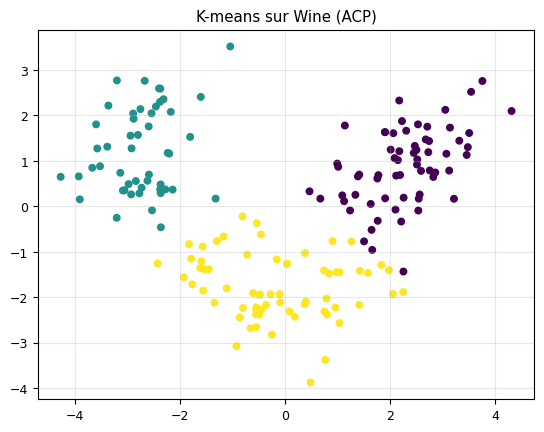

In [52]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : K-means')

from sklearn.cluster import KMeans
modele=KMeans(n_clusters=3,n_init=15,random_state=GRAINE).fit(X_clu)
print('Silhouette:',silhouette_score(X_clu,modele.labels_))
plt.scatter(X_clu[:,0],X_clu[:,1],c=modele.labels_,s=22);plt.title('K-means sur Wine (ACP)');plt.show()

### Lien avec le dataset du projet

**Toujours applicable** (aucune cible requise). **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation, one-hot, standardisation ; comme dans la démonstration Wine, le regroupement se fait dans un espace réduit par ACP (`X_GRP`, 5 axes au plus), et l'affichage sur les deux premiers axes.

[17. K-means] Projet : 3 groupe(s), 0 point(s) de bruit, silhouette = 0.177 | 0.04 s


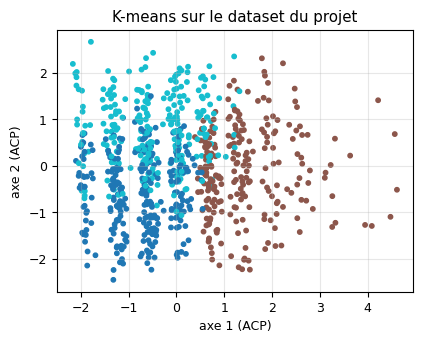

Variation de « n_clusters » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


In [53]:
valeurs = []   # À COMPLÉTER : au moins 5 valeurs de k entre 2 et 8
_ = projet_clustering(17, 'K-means', lambda n_clusters=3: KMeans(n_clusters=n_clusters, n_init=15, random_state=GRAINE), 'n_clusters', valeurs)

**Question projet :** Sur votre dataset, quel nombre de groupes la silhouette suggère-t-elle ? Décrivez chaque groupe par deux ou trois variables qui le distinguent.

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

## 18. Classification hiérarchique

**Question ciblée (Partie B) :** Que montre un dendrogramme et comment définit-on le lien de Ward ?

### Fiche

**1. Descriptif.** La classification ascendante hiérarchique part de $n$ groupes d'un seul point et fusionne à chaque étape les deux groupes les plus proches, jusqu'à n'en avoir qu'un. La notion de proximité entre groupes est fixée par le critère de lien. Avec le lien de Ward, on fusionne la paire qui augmente le moins l'inertie : $\Delta(A,B) = \frac{n_A n_B}{n_A + n_B}\lVert \mu_A - \mu_B \rVert^2$. La suite des fusions forme un arbre, le dendrogramme.

**2. Contexte d'utilisation.** **Cas 1 :** taxonomie ou typologie où la hiérarchie a un sens (espèces, familles de produits). **Cas 2 :** exploration quand le nombre de groupes est inconnu. **À éviter :** plus de quelques dizaines de milliers d'observations (mémoire quadratique), besoin d'affecter de nouveaux points, données très bruitées avec le lien simple.

**3. Type d'apprentissage.** Non supervisé, clustering (hiérarchique ascendant).

**4. Caractéristiques du modèle.** Non paramétrique. Hyperparamètres : `linkage` (ward, complete, average, single), `n_clusters` ou seuil de distance, `metric`. Sensible à l'échelle. Déterministe (pas d'initialisation aléatoire). Les fusions sont définitives. Interprétable par le dendrogramme.

**5. Logique d'apprentissage.** 1) Chaque point est un groupe. 2) Calculer les dissimilarités entre toutes les paires de groupes. 3) Fusionner les deux groupes les plus proches selon le lien. 4) Mettre à jour les dissimilarités (formule de Lance-Williams). 5) Répéter jusqu'à un seul groupe. 6) Couper le dendrogramme à la hauteur voulue pour obtenir $k$ groupes.

**6. Métriques.** Silhouette, corrélation cophénétique (fidélité du dendrogramme aux distances), hauteur des fusions. Limite : pas d'objectif global optimisé, la qualité dépend fortement du lien.

**7. Complexité.** Entraînement : $O(n^2)$ en mémoire (matrice des distances), $O(n^2 \log n)$ à $O(n^3)$ en temps. Pas de prédiction pour de nouveaux points. Mémoire : $O(n^2)$, c'est le facteur limitant.

**8. Version parallèle.** Séquentiel par nature : chaque fusion dépend de la précédente. Seul le calcul initial de la matrice des distances se parallélise. Alternatives à grande échelle : `BisectingKMeans` (descendant, disponible dans Spark MLlib), BIRCH, ou cuML sur GPU pour le lien simple.

### Démonstration sur un jeu public

In [54]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Classification hiérarchique')

from sklearn.cluster import AgglomerativeClustering
etiquettes=AgglomerativeClustering(n_clusters=3,linkage='ward').fit_predict(X_clu)
print('Silhouette:',silhouette_score(X_clu,etiquettes))

Silhouette: 0.5590883962040383


### Lien avec le dataset du projet

**Toujours applicable** (aucune cible requise). **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation, one-hot, standardisation ; comme dans la démonstration Wine, le regroupement se fait dans un espace réduit par ACP (`X_GRP`, 5 axes au plus), et l'affichage sur les deux premiers axes. Si le dataset dépasse 5 000 lignes, garder `N_MAX` à 5 000 (mémoire quadratique).

[18. Classification hiérarchique] Projet : 3 groupe(s), 0 point(s) de bruit, silhouette = 0.134 | 0.02 s


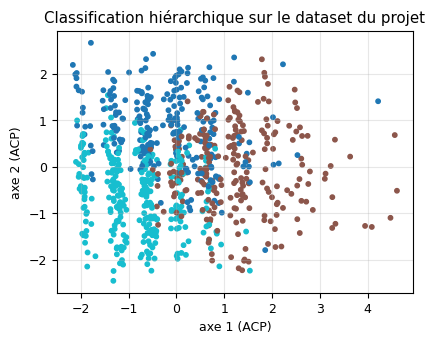

Variation de « linkage » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


In [55]:
valeurs = []   # À COMPLÉTER : les quatre critères de lien
_ = projet_clustering(18, 'Classification hiérarchique', lambda linkage='ward': AgglomerativeClustering(n_clusters=3, linkage=linkage), 'linkage', valeurs)

**Question projet :** Sur votre dataset, les groupes obtenus avec le lien de Ward coïncident-ils avec ceux de K-means (section 17) ? Mesurez-le et interprétez.

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

## 19. DBSCAN

**Question ciblée (Partie B) :** À quoi correspondent les points marqués comme bruit par DBSCAN ?

### Fiche

**1. Descriptif.** DBSCAN regroupe les points situés dans des zones denses et laisse de côté les points isolés. Un point est dit central s'il a au moins `min_samples` voisins dans un rayon $\varepsilon$ : $|N_\varepsilon(x)| \ge \text{min\_samples}$. Les points centraux voisins forment un groupe, auquel se rattachent les points de bordure. Les points qui ne sont ni centraux ni de bordure sont étiquetés bruit ($-1$). Le nombre de groupes n'est pas fixé à l'avance.

**2. Contexte d'utilisation.** **Cas 1 :** données géographiques (zones d'activité, points d'intérêt). **Cas 2 :** groupes de forme quelconque avec valeurs aberrantes à écarter. **À éviter :** groupes de densités très différentes (un seul $\varepsilon$ ne convient pas, voir HDBSCAN), grande dimension (les distances s'uniformisent), besoin d'affecter de nouveaux points.

**3. Type d'apprentissage.** Non supervisé, clustering (par densité), avec détection de bruit.

**4. Caractéristiques du modèle.** Non paramétrique. Hyperparamètres : `eps`, `min_samples`, `metric`. Aucune hypothèse de forme des groupes. Très sensible à l'échelle et au choix de `eps`. Robuste aux valeurs aberrantes (elles deviennent du bruit). Déterministe pour les points centraux.

**5. Logique d'apprentissage.** 1) Pour chaque point, trouver ses voisins à distance au plus $\varepsilon$. 2) Marquer comme centraux les points ayant au moins `min_samples` voisins. 3) Partir d'un point central non visité, créer un groupe et y ajouter de proche en proche tous les points atteignables par des points centraux. 4) Recommencer avec un autre point central non visité. 5) Les points restants sont du bruit.

**6. Métriques.** Nombre de groupes, proportion de bruit, silhouette calculée hors bruit. Limite : la silhouette pénalise les groupes non convexes, que DBSCAN sait justement trouver ; examiner aussi le graphique.

**7. Complexité.** Entraînement : $O(n \log n)$ avec un index spatial en faible dimension, $O(n^2)$ dans le pire cas ou en grande dimension. Pas de prédiction native. Mémoire : $O(n)$ à $O(n^2)$ selon la taille des voisinages.

**8. Version parallèle.** La recherche des voisinages est parallèle (`n_jobs=-1`), l'expansion des groupes de proche en proche est séquentielle. GPU : cuML `DBSCAN`. Spark MLlib ne le fournit pas ; il existe des variantes distribuées par découpage de l'espace.

### Démonstration sur un jeu public

In [56]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : DBSCAN')

from sklearn.cluster import DBSCAN
etiquettes=DBSCAN(eps=.7,min_samples=6).fit_predict(X_clu)
print('Groupes:',len(set(etiquettes)-{-1}),'Bruit:',int((etiquettes==-1).sum()))

Groupes: 2 Bruit: 8


### Lien avec le dataset du projet

**Toujours applicable** (aucune cible requise). **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation, one-hot, standardisation ; comme dans la démonstration Wine, le regroupement se fait dans un espace réduit par ACP (`X_GRP`, 5 axes au plus), et l'affichage sur les deux premiers axes. Le rayon est exprimé en multiple de `EPS_REF`, distance médiane au 6ᵉ voisin calculée en Q0, pour s'adapter à l'échelle de chaque dataset.

[19. DBSCAN] Projet : 7 groupe(s), 219 point(s) de bruit, silhouette = -0.096 | 0.02 s


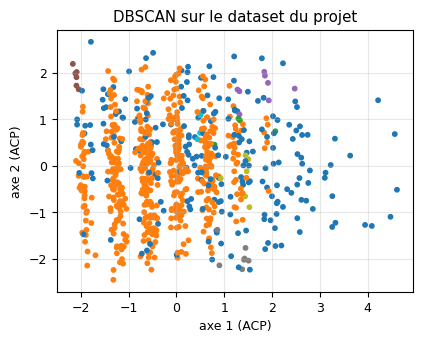

Variation de « eps / EPS_REF » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


In [57]:
valeurs = []   # À COMPLÉTER : au moins 5 multiples de EPS_REF entre 0,5 et 2
_ = projet_clustering(19, 'DBSCAN', lambda coef=1.0: DBSCAN(eps=coef*EPS_REF, min_samples=6), 'eps / EPS_REF', valeurs)

**Question projet :** Sur votre dataset, examinez cinq observations classées comme bruit : sont-elles des erreurs de saisie, des cas rares légitimes ou des cas intéressants pour le projet ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

## 20. Mélanges gaussiens

**Question ciblée (Partie B) :** En quoi les appartenances probabilistes diffèrent-elles d’une affectation dure ?

### Fiche

**1. Descriptif.** Un mélange gaussien suppose que les données proviennent de $k$ lois normales : $p(x) = \sum_{j=1}^{k} \pi_j\, \mathcal N(x ; \mu_j, \Sigma_j)$. Chaque composante a un poids $\pi_j$, un centre $\mu_j$ et une matrice de covariance $\Sigma_j$ qui autorise des groupes elliptiques. Chaque observation reçoit une probabilité d'appartenance à chaque composante. Les paramètres sont estimés par l'algorithme EM.

**2. Contexte d'utilisation.** **Cas 1 :** segments qui se chevauchent, quand on veut un degré d'appartenance. **Cas 2 :** estimation de densité et détection d'anomalies (points de faible vraisemblance). **À éviter :** groupes non elliptiques, grande dimension avec peu de données (covariances mal estimées), nombreuses variables one-hot.

**3. Type d'apprentissage.** Non supervisé, clustering probabiliste (modèle génératif) et estimation de densité.

**4. Caractéristiques du modèle.** Paramétrique ($k$ moyennes, covariances et poids). Hyperparamètres : `n_components`, `covariance_type` (full, tied, diag, spherical), `n_init`. Hypothèse : chaque groupe est gaussien. Sensible à l'échelle, à l'initialisation et aux valeurs aberrantes. Interprétable par les moyennes et covariances.

**5. Logique d'apprentissage.** Objectif : maximiser la log-vraisemblance $\sum_i \log p(x_i)$ par EM. 1) Initialiser (souvent par K-means). 2) Étape E : calculer les responsabilités $\gamma_{ij} = \frac{\pi_j \mathcal N(x_i ; \mu_j, \Sigma_j)}{\sum_l \pi_l \mathcal N(x_i ; \mu_l, \Sigma_l)}$. 3) Étape M : recalculer $\pi_j$, $\mu_j$, $\Sigma_j$ comme moyennes pondérées par les $\gamma_{ij}$. 4) Répéter jusqu'à ce que la vraisemblance ne progresse plus.

**6. Métriques.** BIC et AIC pour choisir $k$ (plus bas = meilleur), log-vraisemblance moyenne, silhouette sur les affectations dures. Limite : la vraisemblance augmente toujours avec $k$, d'où le recours au BIC qui pénalise la complexité.

**7. Complexité.** Entraînement : $O(n \cdot k \cdot p^2)$ par itération en covariance pleine, plus $O(k p^3)$ pour les factorisations. Prédiction : $O(k p^2)$. Mémoire : $O(k p^2)$ pour le modèle.

**8. Version parallèle.** L'étape E est indépendante par observation (map), l'étape M agrège des sommes pondérées (reduce) : Spark MLlib `GaussianMixture` l'exploite. scikit-learn n'a pas de `n_jobs` mais s'appuie sur BLAS ; les `n_init` initialisations sont indépendantes et pourraient tourner en parallèle.

### Démonstration sur un jeu public

In [58]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Mélanges gaussiens')

from sklearn.mixture import GaussianMixture
modele=GaussianMixture(n_components=3,covariance_type='full',random_state=GRAINE).fit(X_clu)
etiquettes=modele.predict(X_clu)
print('Poids des groupes:',modele.weights_.round(3),'Silhouette:',silhouette_score(X_clu,etiquettes))

Poids des groupes: [0.38  0.269 0.351] Silhouette: 0.5591116207103001


### Lien avec le dataset du projet

**Toujours applicable** (aucune cible requise). **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation, one-hot, standardisation ; comme dans la démonstration Wine, le regroupement se fait dans un espace réduit par ACP (`X_GRP`, 5 axes au plus), et l'affichage sur les deux premiers axes. L'espace réduit par ACP évite les covariances dégénérées dues aux colonnes one-hot.

[20. Mélanges gaussiens] Projet : 3 groupe(s), 0 point(s) de bruit, silhouette = 0.152 | 0.03 s


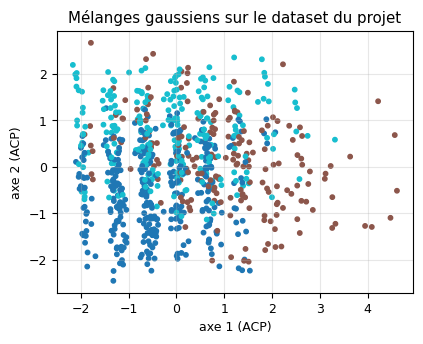

Variation de « n_components » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


In [59]:
valeurs = []   # À COMPLÉTER : au moins 4 nombres de composantes entre 2 et 6
_ = projet_clustering(20, 'Mélanges gaussiens', lambda n_components=3: GaussianMixture(n_components=n_components, covariance_type='full', random_state=GRAINE), 'n_components', valeurs)

**Question projet :** Sur votre dataset, combien d'observations ont une probabilité d'appartenance maximale inférieure à 0,6 ? Que représentent-elles pour le projet ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

# Partie 4. Apprentissage non supervisé : réduction de dimension et anomalies (sections 21 à 24)

In [60]:
# Jeu public utilisé par les démonstrations de cette partie
q0('dig', 3)

Dimensions : (1797, 65)


,px0,px1,px2,px3,px4,px5,px6,px7,px8,px9,...,px55,px56,px57,px58,px59,px60,px61,px62,px63,chiffre
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2


## 21. ACP

**Question ciblée (Partie B) :** Que mesure la variance expliquée par les deux axes de l’ACP ?

### Fiche

**1. Descriptif.** L'analyse en composantes principales cherche de nouveaux axes orthogonaux, combinaisons linéaires des variables, le long desquels la variance des données est maximale. Les axes sont les vecteurs propres de la matrice de covariance : $\Sigma v_j = \lambda_j v_j$, et la valeur propre $\lambda_j$ est la variance portée par l'axe $j$. En gardant les $k$ premiers axes, on résume les données avec une perte d'information minimale au sens des moindres carrés.

**2. Contexte d'utilisation.** **Cas 1 :** visualiser en 2D des données à nombreuses variables. **Cas 2 :** décorréler et compresser avant un autre modèle, ou débruiter. **À éviter :** structure non linéaire (variété courbe), variables catégorielles (préférer l'ACM), cas où les axes doivent garder le sens des variables d'origine.

**3. Type d'apprentissage.** Non supervisé, réduction de dimension linéaire.

**4. Caractéristiques du modèle.** Linéaire, déterministe. Hyperparamètres : `n_components`, `svd_solver`. Hypothèse : la variance est le signal utile. Très sensible à l'échelle (standardiser) et aux valeurs aberrantes. Sait projeter de nouveaux points et revenir à l'espace d'origine. Interprétable par les contributions des variables aux axes.

**5. Logique d'apprentissage.** 1) Centrer (et réduire) $X$. 2) Calculer la décomposition en valeurs singulières $X = U S V^\top$. 3) Les colonnes de $V$ sont les axes principaux ; les variances sont $\lambda_j = s_j^2 / (n-1)$. 4) Projeter : $Z = X V_k$. 5) Part de variance de l'axe $j$ : $\lambda_j / \sum_l \lambda_l$.

**6. Métriques.** Part de variance expliquée et son cumul (éboulis des valeurs propres), erreur de reconstruction. Limite : beaucoup de variance ne signifie pas pertinence pour la tâche (un axe de faible variance peut séparer les classes).

**7. Complexité.** Entraînement : $O(\min(n p^2, n^2 p))$ en SVD complète, $O(n p k)$ en SVD aléatoire pour $k$ axes. Projection : $O(p k)$ par observation. Mémoire : $O(n p)$.

**8. Version parallèle.** L'algèbre linéaire est multi-cœur (BLAS/LAPACK). La matrice de covariance est une somme sur les observations, donc distribuable (Spark MLlib `PCA`). `IncrementalPCA` traite les données par lots hors mémoire. Dask-ML et cuML (GPU) proposent aussi l'ACP.

### Démonstration sur un jeu public

Variance expliquée: [0.12  0.096]


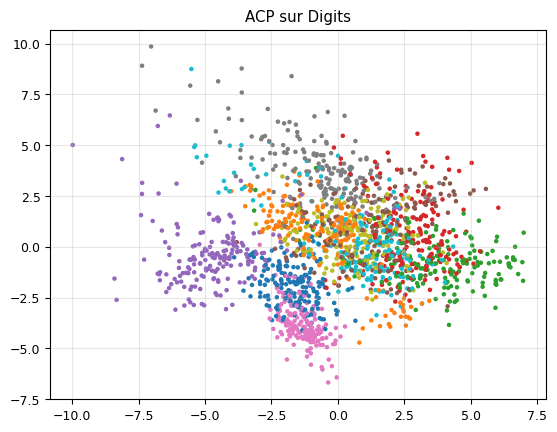

In [61]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : ACP')

from sklearn.decomposition import PCA
modele=PCA(n_components=2,random_state=GRAINE).fit(X_images)
projection=modele.transform(X_images)
print('Variance expliquée:',modele.explained_variance_ratio_.round(3))
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target,cmap='tab10',s=5);plt.title('ACP sur Digits');plt.show()

### Lien avec le dataset du projet

**Toujours applicable** (aucune cible requise). **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation, one-hot, standardisation ; aucune autre exigence. Les points sont colorés par `CIBLE_CLASSIFICATION` si elle est définie, à titre d'illustration uniquement.

[21. ACP] Projet : variance (2 axes) = 38.0 %, confiance = 0.794 | 0.00 s


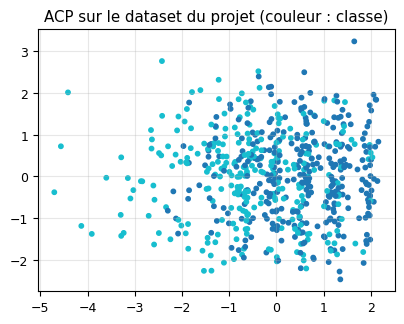

Variation de « n_components » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


In [62]:
valeurs = []   # À COMPLÉTER : au moins 4 nombres d'axes entre 1 et 8
_ = projet_projection(21, 'ACP', lambda n_components=2: PCA(n_components=n_components, random_state=GRAINE), 'n_components', valeurs)

**Question projet :** Sur votre dataset, combien d'axes faut-il pour atteindre 80 % de variance expliquée ? Quelles variables contribuent le plus au premier axe ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

## 22. t-SNE

**Question ciblée (Partie B) :** Pourquoi la distance entre groupes éloignés peut-elle être trompeuse en t-SNE ?

### Fiche

**1. Descriptif.** t-SNE construit une carte en 2D qui préserve les voisinages locaux. Il transforme les distances en probabilités de voisinage $p_{ij}$ (noyau gaussien) dans l'espace d'origine, et $q_{ij}$ (loi de Student) dans la carte, puis déplace les points pour minimiser la divergence $KL(P \,\|\, Q) = \sum_{i \ne j} p_{ij} \log \frac{p_{ij}}{q_{ij}}$. La perplexité règle la taille du voisinage pris en compte. Le résultat sert à la visualisation.

**2. Contexte d'utilisation.** **Cas 1 :** explorer visuellement des représentations vectorielles (embeddings de mots, d'images). **Cas 2 :** vérifier si des classes forment des amas distincts avant de modéliser. **À éviter :** réduction de dimension en amont d'un modèle (pas de transformation des nouveaux points), mesure de distances ou de tailles de groupes sur la carte, très grands jeux sans variante accélérée.

**3. Type d'apprentissage.** Non supervisé, réduction de dimension non linéaire (visualisation).

**4. Caractéristiques du modèle.** Non paramétrique, non linéaire, stochastique. Hyperparamètres : `perplexity`, `learning_rate`, `max_iter`, `init`. Sensible à l'échelle et à la graine. Ne sait pas projeter de nouveaux points. Préserve le local, pas le global. Les axes n'ont pas de signification.

**5. Logique d'apprentissage.** 1) Pour chaque point, régler la largeur du noyau gaussien pour atteindre la perplexité voulue, et calculer les $p_{ij}$. 2) Initialiser la carte (par ACP). 3) Calculer les $q_{ij} \propto (1 + \lVert z_i - z_j \rVert^2)^{-1}$. 4) Descendre le gradient de la divergence KL (attraction des voisins, répulsion des autres). 5) Répéter quelques centaines d'itérations.

**6. Métriques.** Divergence KL finale, indice de confiance (`trustworthiness`, proche de 1 si les voisins sur la carte étaient déjà voisins à l'origine). Limite : la KL ne se compare pas entre perplexités différentes.

**7. Complexité.** Entraînement : $O(n^2)$ par itération en version exacte, $O(n \log n)$ avec l'approximation de Barnes-Hut. Pas de prédiction. Mémoire : $O(n)$ avec Barnes-Hut, $O(n^2)$ en exact.

**8. Version parallèle.** Dans scikit-learn, `n_jobs` ne parallélise que la recherche des voisins ; la descente de gradient est mono-fil. Variantes parallèles : openTSNE et Multicore-TSNE (multi-cœurs, accélération par FFT), cuML et t-SNE-CUDA (GPU). Absent de Spark MLlib.

### Démonstration sur un jeu public

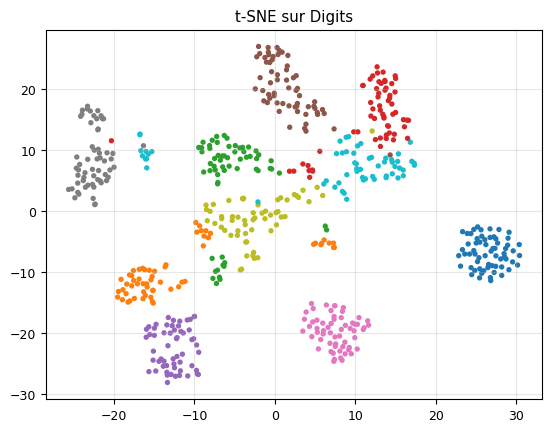

In [63]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : t-SNE')

from sklearn.manifold import TSNE
projection=TSNE(n_components=2,perplexity=35,random_state=GRAINE,init='pca').fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('t-SNE sur Digits');plt.show()

### Lien avec le dataset du projet

**Toujours applicable** (aucune cible requise). **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation, one-hot, standardisation ; la carte est calculée sur 600 observations au plus (`N_VISU`) pour rester rapide.

[22. t-SNE] Projet : confiance = 0.940 | 4.93 s


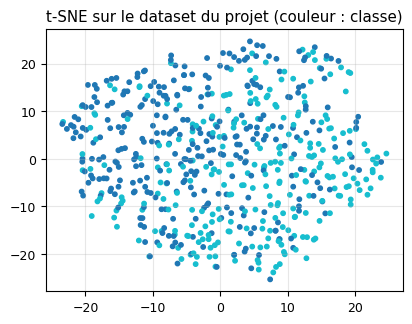

Variation de « perplexity » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


In [64]:
valeurs = []   # À COMPLÉTER : au moins 3 perplexités entre 5 et 50
_ = projet_projection(22, 't-SNE', lambda perplexity=35: TSNE(n_components=2, perplexity=min(perplexity, (len(X_VISU)-1)/3), random_state=GRAINE, init='pca'), 'perplexity', valeurs)

**Question projet :** Sur votre dataset, les amas visibles sur la carte t-SNE correspondent-ils à une variable connue (classe, catégorie) ? Laquelle, et qu'en concluez-vous ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

## 23. UMAP

**Question ciblée (Partie B) :** Quel est l’effet de n_neighbors et min_dist sur les voisinages ?

### Fiche

**1. Descriptif.** UMAP construit un graphe pondéré des plus proches voisins dans l'espace d'origine, puis cherche une disposition en faible dimension dont le graphe lui ressemble. Il minimise une entropie croisée entre les poids des arêtes d'origine $v_{ij}$ et ceux de la carte $w_{ij}$ : $\sum_{i \ne j} \left[v_{ij} \log \frac{v_{ij}}{w_{ij}} + (1 - v_{ij}) \log \frac{1 - v_{ij}}{1 - w_{ij}}\right]$. Il est plus rapide que t-SNE et conserve mieux la structure globale.

**2. Contexte d'utilisation.** **Cas 1 :** visualiser de grands jeux (cellules en génomique, embeddings). **Cas 2 :** réduire la dimension avant un clustering, car UMAP sait transformer de nouveaux points. **À éviter :** interprétation fine des distances ou des densités sur la carte, tout petits jeux (moins de points que de voisins), besoin d'axes interprétables.

**3. Type d'apprentissage.** Non supervisé, réduction de dimension non linéaire.

**4. Caractéristiques du modèle.** Non paramétrique (variante paramétrique par réseau de neurones disponible), non linéaire, stochastique. Hyperparamètres : `n_neighbors`, `min_dist`, `n_components`, `metric`. Sensible à l'échelle et à la graine. Sait projeter de nouveaux points (`transform`). Axes sans signification.

**5. Logique d'apprentissage.** 1) Chercher les `n_neighbors` plus proches voisins de chaque point (algorithme approché NN-descent). 2) Pondérer les arêtes par une décroissance exponentielle de la distance, adaptée localement, puis symétriser. 3) Initialiser la carte (plongement spectral). 4) Optimiser par descente de gradient stochastique : rapprocher les points reliés, écarter des points tirés au hasard. `min_dist` fixe la distance minimale entre points sur la carte.

**6. Métriques.** Indice de confiance (`trustworthiness`), conservation des $k$ plus proches voisins. Limite : aucune mesure ne résume à elle seule la fidélité globale ; comparer plusieurs graines.

**7. Complexité.** Entraînement : environ $O(n^{1,14})$ pour la recherche approchée des voisins, puis $O(n \cdot \text{n\_neighbors} \cdot \text{époques})$ pour l'optimisation. Projection d'un nouveau point : recherche de voisins puis quelques itérations. Mémoire : $O(n \cdot \text{n\_neighbors})$.

**8. Version parallèle.** La recherche des voisins et l'optimisation sont parallélisées par numba sur les cœurs. Attention : fixer `random_state` force l'exécution sur un seul fil pour garantir la reproductibilité. GPU : cuML `UMAP`, bien plus rapide sur de gros volumes.

### Démonstration sur un jeu public

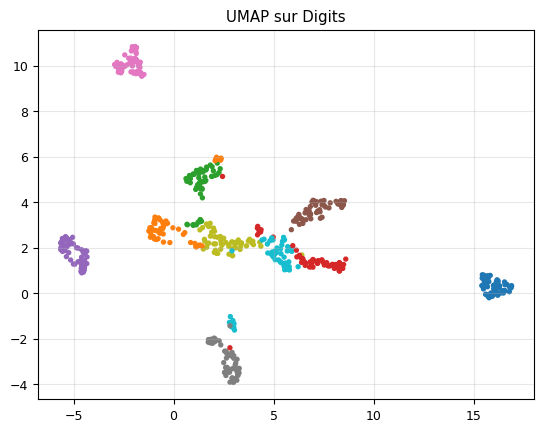

In [65]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : UMAP')

import umap
projection=umap.UMAP(n_components=2,n_neighbors=20,min_dist=.15,random_state=GRAINE).fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('UMAP sur Digits');plt.show()

### Lien avec le dataset du projet

**Toujours applicable** (aucune cible requise). **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation, one-hot, standardisation ; la carte est calculée sur 600 observations au plus (`N_VISU`).

In [ ]:
valeurs = []   # À COMPLÉTER : au moins 3 valeurs de n_neighbors entre 5 et 50
_ = projet_projection(23, 'UMAP', lambda n_neighbors=20: umap.UMAP(n_components=2, n_neighbors=min(n_neighbors, len(X_VISU)-1), min_dist=.15, random_state=GRAINE), 'n_neighbors', valeurs)

**Question projet :** Sur votre dataset, UMAP et t-SNE montrent-ils les mêmes amas ? Lequel utiliseriez-vous dans le rapport du projet et pourquoi ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

## 24. Isolation Forest

**Question ciblée (Partie B) :** Pourquoi une observation statistiquement atypique n’est-elle pas forcément une erreur ?

### Fiche

**1. Descriptif.** Isolation Forest détecte les anomalies en mesurant la facilité avec laquelle une observation peut être isolée par des coupures aléatoires. Chaque arbre choisit une variable et un seuil au hasard jusqu'à isoler chaque point. Une anomalie, rare et différente, est isolée en peu de coupures. Le score est $s(x) = 2^{-E[h(x)]/c(\psi)}$, où $E[h(x)]$ est la profondeur moyenne de $x$ dans les arbres et $c(\psi)$ une constante de normalisation : proche de 1, le point est suspect.

**2. Contexte d'utilisation.** **Cas 1 :** détection de fraude ou d'intrusion sans exemples étiquetés. **Cas 2 :** nettoyage d'un jeu de données avant modélisation, surveillance de capteurs. **À éviter :** anomalies définies par un contexte (une valeur normale en été, anormale en hiver), anomalies regroupées en amas denses, cas où des étiquettes existent (préférer le supervisé).

**3. Type d'apprentissage.** Non supervisé, détection d'anomalies.

**4. Caractéristiques du modèle.** Non paramétrique, ensemble d'arbres aléatoires. Hyperparamètres : `contamination` (proportion attendue d'anomalies), `n_estimators`, `max_samples`. Aucune hypothèse de loi. Peu sensible à l'échelle (coupures par variable). Interprétabilité faible : le score ne dit pas pourquoi le point est atypique.

**5. Logique d'apprentissage.** Pour chaque arbre : 1) tirer un sous-échantillon de $\psi$ points (256 par défaut). 2) Choisir une variable au hasard, puis un seuil au hasard entre son minimum et son maximum. 3) Diviser et recommencer jusqu'à isoler chaque point. Score : 4) mesurer la profondeur de $x$ dans chaque arbre. 5) Moyenner et normaliser. 6) Signaler les points dont le score dépasse le seuil fixé par `contamination`.

**6. Métriques.** Sans étiquettes : proportion signalée, distribution des scores, examen manuel des cas. Avec quelques étiquettes : précision parmi les $k$ premiers, AUC-ROC, AUC précision-rappel. Limite : `contamination` fixe le nombre de cas signalés, pas leur réalité.

**7. Complexité.** Entraînement : $O(T \cdot \psi \cdot \log \psi)$, indépendant de $n$ grâce au sous-échantillonnage. Score : $O(T \cdot \log \psi)$ par observation. Mémoire : $O(T \cdot \psi)$.

**8. Version parallèle.** Parallélisme total : les arbres sont indépendants (`n_jobs=-1`), et le calcul des scores est indépendant par observation. Sur Spark : bibliothèques tierces (isolation-forest de LinkedIn, SynapseML), pas dans MLlib de base.

### Démonstration sur un jeu public

In [66]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Isolation Forest')

from sklearn.ensemble import IsolationForest
# Recherche d'observations atypiques dans les caractéristiques de vins (sans ajouter de faux points)
modele=IsolationForest(contamination=.05,n_estimators=150,random_state=GRAINE).fit(X_clu)
indices=np.where(modele.predict(X_clu)==-1)[0]
print('Nombre de vins atypiques:',len(indices),'Indices (extrait):',indices[:12])

Nombre de vins atypiques: 9 Indices (extrait): [  3  14  18  59  80 115 146 158 177]


### Lien avec le dataset du projet

**Toujours applicable** (aucune cible requise). **Variables :** toutes les colonnes sauf les cibles et `COLONNES_A_IGNORER`. **Prétraitement exigé :** imputation, one-hot, standardisation ; aucune autre exigence. Les cinq observations les plus atypiques du dataset sont affichées pour examen.

[24. Isolation Forest] Projet : 40 observations signalées (5.0 %) | 1.49 s
Les cinq observations les plus atypiques :


,id_client,anciennete_mois,age,usage_go,appels_support,satisfaction,offre,canal,region,depense_mensuelle,resilie,score
233,234,20,26,12.9,5,1.0,Confort,telephone,Sud,39.79,1,0.623
345,346,37,61,80.6,5,1.0,Confort,web,Est,100.45,1,0.621
773,774,72,57,12.2,4,2.0,Premium,telephone,Sud,61.14,1,0.616
691,692,5,63,27.8,3,1.0,Premium,telephone,Ouest,66.17,1,0.614
190,191,31,55,5.6,3,1.0,Premium,boutique,Sud,53.58,1,0.613


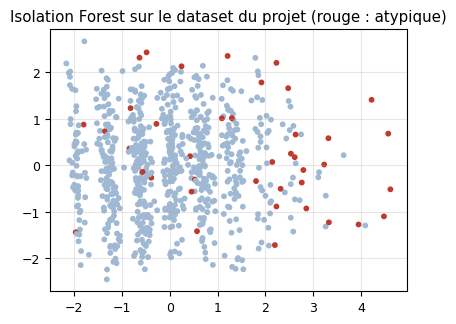

Variation de « contamination » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


In [67]:
valeurs = []   # À COMPLÉTER : au moins 3 taux de contamination entre 0,01 et 0,2
_ = projet_anomalies(24, 'Isolation Forest', lambda contamination=.05: IsolationForest(contamination=contamination, n_estimators=150, random_state=GRAINE, n_jobs=-1), 'contamination', valeurs)

**Question projet :** Sur votre dataset, examinez les cinq observations les plus atypiques : qu'est-ce qui les rend inhabituelles, et faut-il les retirer, les corriger ou les garder ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

# Partie 5. Apprentissage par renforcement (sections 25 à 29)

## 25. Bandits manchots

**Question ciblée (Partie B) :** Comment calculer une estimation du gain moyen de chaque bras ?

### Fiche

**1. Descriptif.** Le problème du bandit manchot modélise un choix répété entre $K$ actions (bras) dont les gains sont aléatoires et de moyennes inconnues. À chaque pas, l'agent tire un bras et observe seulement le gain de ce bras. Il estime la valeur de chaque bras par la moyenne des gains obtenus : $\hat Q_t(a) = \frac{1}{N_t(a)} \sum_{s \le t,\, a_s = a} r_s$. L'objectif est de maximiser le gain cumulé, ce qui impose d'arbitrer entre exploration et exploitation.

**2. Contexte d'utilisation.** **Cas 1 :** tests A/B adaptatifs (choisir la meilleure variante d'une page). **Cas 2 :** recommandation de contenus ou allocation de traitements en essai clinique adaptatif. **À éviter :** quand l'action modifie la situation future (il faut alors un état : Q-learning), quand les gains dépendent fortement du contexte (bandits contextuels), quand on ne peut pas expérimenter en ligne.

**3. Type d'apprentissage.** Apprentissage par renforcement, cas sans état (un seul état, décision séquentielle avec retour partiel).

**4. Caractéristiques du modèle.** Modèle tabulaire : une estimation et un compteur par bras. Paramètres : nombre de bras, politique de choix, horizon. Hypothèse : gains stationnaires et indépendants. La politique de la démonstration (tourniquet) explore uniformément sans jamais exploiter. Très interprétable.

**5. Logique d'apprentissage.** 1) Initialiser $\hat Q(a) = 0$ et $N(a) = 0$ pour chaque bras. 2) À chaque pas, choisir un bras $a$ selon la politique (ici à tour de rôle). 3) Observer le gain $r$. 4) Mettre à jour de façon incrémentale : $N(a) \leftarrow N(a) + 1$, puis $\hat Q(a) \leftarrow \hat Q(a) + \frac{1}{N(a)}\left(r - \hat Q(a)\right)$.

**6. Métriques.** Regret cumulé $R_T = T \mu^* - \sum_t \mu_{a_t}$ (manque à gagner par rapport au meilleur bras), gain cumulé, erreur d'estimation des moyennes. Limite : le regret n'est calculable qu'en simulation, où les vraies moyennes sont connues.

**7. Complexité.** Temps : $O(1)$ par pas pour la mise à jour, $O(T)$ au total. Mémoire : $O(K)$. Précision de l'estimation d'un bras : erreur de l'ordre de $1/\sqrt{N(a)}$.

**8. Version parallèle.** L'interaction est séquentielle par nature : chaque décision dépend des gains précédents. On peut toutefois servir plusieurs utilisateurs en parallèle avec des mises à jour par lots (bandits en lots, retour différé). Les simulations répétées (plusieurs graines) sont indépendantes et se parallélisent totalement.

### Démonstration sur un jeu public

In [68]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Bandits manchots')

# Bandit simulé à 4 choix : la politique choisit successivement chaque bras
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int)
for t in range(800):
    bras=t%4
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Probabilités estimées:',(sommes/comptes).round(3))

Probabilités estimées: [0.205 0.335 0.605 0.765]


### Lien avec le dataset du projet

**Applicable sous forme de simulation** si `CIBLE_CLASSIFICATION` est définie et si le dataset contient une colonne catégorielle de 2 à 10 modalités (`COLONNE_BRAS`, choisie automatiquement sinon). **Bras :** les modalités de cette colonne. **Gain :** 1 si la cible vaut `CLASSE_SUCCES`, 0 sinon. Les taux de succès observés par modalité servent de probabilités de gain. Réserve importante : c'est une simulation construite sur des fréquences historiques, pas une expérience en ligne, et ces fréquences ne sont pas des effets causaux. **Prétraitement :** aucun.

[25. Bandits manchots] Projet (simulation) : bras = modalités de 'offre', gain = 1 si resilie = 0


,taux observé,estimation,tirages
offre,,,
Confort,0.582,0.577,267
Essentiel,0.479,0.502,267
Premium,0.545,0.545,266


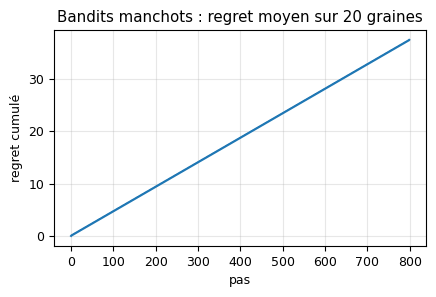

Variation de « horizon T » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


In [69]:
valeurs = []   # À COMPLÉTER : au moins 3 horizons entre 40 et 4000
_ = projet_bandit(25, 'Bandits manchots', 'tourniquet', 'horizon T', valeurs)

**Question projet :** Dans votre projet, existe-t-il une décision répétée qui pourrait se formuler comme un bandit (bras, gain, horizon) ? Décrivez-la ou expliquez pourquoi il n'y en a pas.

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

## 26. Epsilon-greedy

**Question ciblée (Partie B) :** Quelle différence entre exploration aléatoire et exploitation du meilleur bras estimé ?

### Fiche

**1. Descriptif.** Epsilon-greedy est la politique la plus simple pour arbitrer entre exploration et exploitation dans un bandit. À chaque pas, avec la probabilité $\varepsilon$ l'agent tire un bras au hasard (exploration), sinon il tire le bras de meilleure estimation $\arg\max_a \hat Q(a)$ (exploitation). Les estimations sont mises à jour comme des moyennes. La valeur de $\varepsilon$ fixe la part du temps consacrée à explorer.

**2. Contexte d'utilisation.** **Cas 1 :** optimisation en ligne d'une bannière ou d'un prix parmi quelques options. **Cas 2 :** politique d'exploration à l'intérieur du Q-learning et du DQN. **À éviter :** quand chaque essai coûte cher ou présente un risque (l'exploration est aveugle), quand il y a beaucoup de bras (préférer UCB ou Thompson), environnement non stationnaire sans adaptation.

**3. Type d'apprentissage.** Apprentissage par renforcement, cas sans état (politique d'exploration).

**4. Caractéristiques du modèle.** Tabulaire : une estimation et un compteur par bras. Hyperparamètre : `epsilon` (fixe ou décroissant), valeurs initiales. Hypothèse : gains stationnaires. Avec $\varepsilon$ fixe, le regret reste linéaire (on explore pour toujours) ; avec $\varepsilon$ décroissant, il peut devenir logarithmique. Très interprétable.

**5. Logique d'apprentissage.** À chaque pas $t$ : 1) tirer $u$ uniforme sur $[0,1]$. 2) Si $u < \varepsilon$ : choisir un bras au hasard ; sinon choisir $\arg\max_a \hat Q(a)$. 3) Observer le gain $r$. 4) Mettre à jour $\hat Q(a) \leftarrow \hat Q(a) + \frac{1}{N(a)}(r - \hat Q(a))$.

**6. Métriques.** Regret cumulé, gain moyen par pas, proportion de tirages du meilleur bras. Limite : résultats très variables d'une exécution à l'autre, il faut moyenner sur plusieurs graines.

**7. Complexité.** Temps : $O(K)$ par pas pour l'argmax (ou $O(1)$ en suivant le maximum). Mémoire : $O(K)$. Regret : $O(\varepsilon T)$ pour $\varepsilon$ fixe.

**8. Version parallèle.** Décision séquentielle par nature. Parallélisme possible : simulations indépendantes sur plusieurs graines, ou mise à jour par lots quand plusieurs utilisateurs sont servis en même temps. Bibliothèques : Vowpal Wabbit, Ray RLlib (bandits).

### Démonstration sur un jeu public

In [70]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Epsilon-greedy')

# Epsilon-greedy sur les mêmes 4 bras simulés
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int);epsilon=.15
for t in range(1200):
    bras=int(generateur.integers(4)) if generateur.random()<epsilon else int(np.argmax((sommes+1)/(comptes+2)))
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Nombre de choix:',comptes,'Estimations:',(sommes/np.maximum(comptes,1)).round(3))

Nombre de choix: [  55   53   44 1048] Estimations: [0.182 0.377 0.614 0.751]


### Lien avec le dataset du projet

**Applicable sous forme de simulation**, dans les mêmes conditions et avec les mêmes réserves que la section 25 (bras = modalités de `COLONNE_BRAS`, gain = cible égale à `CLASSE_SUCCES`). Le regret est moyenné sur 20 graines. **Prétraitement :** aucun.

[26. Epsilon-greedy] Projet (simulation) : bras = modalités de 'offre', gain = 1 si resilie = 0


,taux observé,estimation,tirages
offre,,,
Confort,0.582,0.591,1059
Essentiel,0.479,0.469,64
Premium,0.545,0.494,77


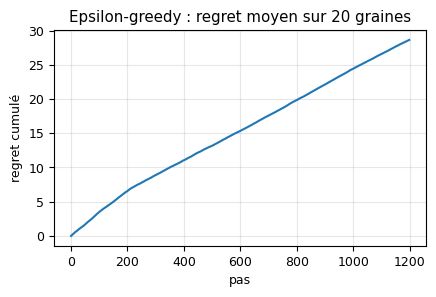

Variation de « epsilon » : À COMPLÉTER (remplir la liste valeurs puis relancer la cellule).


In [71]:
valeurs = []   # À COMPLÉTER : au moins 5 valeurs d'epsilon entre 0 et 1, bornes comprises
_ = projet_bandit(26, 'Epsilon-greedy', 'epsilon-greedy', 'epsilon', valeurs)

**Question projet :** Avec les bras de votre dataset, quelle valeur d'epsilon donne le plus faible regret ? Les taux de succès des bras sont-ils proches ou bien séparés, et en quoi cela influence-t-il la réponse ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

## 27. Q-learning

**Question ciblée (Partie B) :** Comment calculer une cible de Bellman dans Taxi et pourquoi le max intervient-il ?

### Fiche

**1. Descriptif.** Le Q-learning apprend, par essais et erreurs, la valeur $Q(s,a)$ de chaque action dans chaque état : le gain cumulé actualisé espéré si l'on joue $a$ dans $s$ puis que l'on agit au mieux. Après chaque transition $(s, a, r, s')$, il applique la mise à jour $Q(s,a) \leftarrow Q(s,a) + \alpha\left[r + \gamma \max_{a'} Q(s',a') - Q(s,a)\right]$. Il n'a pas besoin de modèle de l'environnement. La politique finale consiste à choisir l'action de plus grande valeur.

**2. Contexte d'utilisation.** **Cas 1 :** contrôle dans un environnement discret de petite taille (navigation sur grille, gestion de stock simplifiée). **Cas 2 :** apprentissage en simulation d'une stratégie de jeu simple. **À éviter :** espace d'états grand ou continu (la table explose : passer au DQN), exploration réelle coûteuse ou dangereuse, absence de simulateur.

**3. Type d'apprentissage.** Apprentissage par renforcement, sans modèle, hors politique (off-policy), par différence temporelle.

**4. Caractéristiques du modèle.** Tabulaire : une valeur par couple (état, action). Hyperparamètres : taux d'apprentissage $\alpha$, facteur d'actualisation $\gamma$, calendrier de $\varepsilon$, nombre d'épisodes. Hypothèse : processus de décision markovien. Converge vers $Q^*$ si chaque couple est visité indéfiniment et si $\alpha$ décroît. Interprétable par la table.

**5. Logique d'apprentissage.** 1) Initialiser $Q = 0$. 2) Pour chaque épisode, partir d'un état $s$. 3) Choisir $a$ par epsilon-greedy sur $Q(s, \cdot)$. 4) Jouer $a$, observer $r$ et $s'$. 5) Calculer la cible $y = r + \gamma \max_{a'} Q(s', a')$ (ou $y = r$ si $s'$ est terminal). 6) Mettre à jour $Q(s,a) \leftarrow Q(s,a) + \alpha (y - Q(s,a))$. 7) $s \leftarrow s'$ et recommencer jusqu'à la fin de l'épisode.

**6. Métriques.** Récompense cumulée moyenne par épisode, taux de réussite, nombre de pas par épisode, courbe d'apprentissage. Évaluer avec la politique gloutonne (sans exploration) sur des épisodes distincts.

**7. Complexité.** Temps : $O(|A|)$ par pas (calcul du maximum). Mémoire : $O(|S| \cdot |A|)$, soit $500 \times 6$ pour Taxi. Le nombre d'épisodes nécessaires croît avec $|S| \cdot |A|$.

**8. Version parallèle.** Dans un épisode, les mises à jour sont séquentielles (chaque état dépend de l'action précédente). On parallélise la collecte : plusieurs environnements simultanés (`gymnasium.vector`) ou plusieurs acteurs asynchrones qui mettent à jour une table partagée. Bibliothèque : Ray RLlib.

### Démonstration sur un jeu public

In [72]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : Q-learning')

# Q-learning manuel sur Taxi : exploration epsilon-greedy
import gymnasium as gym
TAXI_ID = 'Taxi-v4' if 'Taxi-v4' in gym.registry else 'Taxi-v3'   # Taxi-v3 supprimé dans les versions récentes

def evaluer(Q, episodes=200):
    # Politique gloutonne (sans exploration) sur des épisodes non vus pendant l'entraînement
    env=gym.make(TAXI_ID); total=[]; reussites=0
    for e in range(episodes):
        etat,_=env.reset(seed=100000+e); somme=0
        for pas in range(200):
            etat,recompense,termine,tronque,_=env.step(int(np.argmax(Q[etat]))); somme+=recompense
            if termine or tronque: break
        total.append(somme); reussites+=int(termine)
    env.close(); return float(np.mean(total)), reussites/episodes

env=gym.make(TAXI_ID)
Q=np.zeros((env.observation_space.n,env.action_space.n))
generateur=np.random.default_rng(GRAINE)
for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode)
    epsilon=max(.07,1-episode/2400)
    for pas in range(200):
        action=int(generateur.integers(env.action_space.n)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
        suivant,recompense,termine,tronque,_=env.step(action)
        cible=recompense+(0 if termine else .96*np.max(Q[suivant]))   # cible de Bellman : max sur les actions suivantes
        Q[etat,action]+=.2*(cible-Q[etat,action])
        etat=suivant
        if termine or tronque:break
env.close()
Q_qlearning=Q.copy()
print('Environnement :',TAXI_ID)
print('Q-learning Taxi : taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2))
print('Évaluation gloutonne : récompense moyenne %.2f, taux de réussite %.0f %%' % (evaluer(Q)[0], 100*evaluer(Q)[1]))

Environnement : Taxi-v4
Q-learning Taxi : taille de Q: (500, 6) Valeurs du premier état: [0. 0. 0. 0. 0. 0.]
Évaluation gloutonne : récompense moyenne 7.98, taux de réussite 100 %


### Lien avec le dataset du projet

**Non applicable directement.** Un dataset tabulaire figé ne fournit ni états successifs, ni actions, ni récompenses : il n'y a pas d'environnement avec lequel interagir. Le Q-learning ne s'appliquerait que si le projet comportait une décision séquentielle simulable (par exemple une politique de relance client étape par étape). La démonstration Taxi est donc conservée.

In [73]:
enregistrer(27, 'Q-learning', 'non applicable (pas d\'environnement)')

[27. Q-learning] Projet : non applicable (pas d'environnement).


**Question projet :** Imaginez une décision séquentielle liée à votre projet. Définissez ses états, ses actions et sa récompense, et estimez la taille de la table Q. Est-elle réaliste ?

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

## 28. SARSA

**Question ciblée (Partie B) :** Pourquoi SARSA met-il à jour Q avec l’action suivante réellement choisie ?

### Fiche

**1. Descriptif.** SARSA apprend la valeur $Q(s,a)$ de la politique que l'agent suit réellement, exploration comprise. Son nom vient du quintuplet utilisé à chaque mise à jour : $(s, a, r, s', a')$. La règle est $Q(s,a) \leftarrow Q(s,a) + \alpha\left[r + \gamma\, Q(s',a') - Q(s,a)\right]$, où $a'$ est l'action effectivement choisie dans $s'$. À la différence du Q-learning, il n'y a pas de maximum : la cible tient compte des écarts dus à l'exploration.

**2. Contexte d'utilisation.** **Cas 1 :** apprentissage en ligne où les erreurs d'exploration coûtent cher (robot près d'un obstacle) : SARSA apprend un comportement plus prudent. **Cas 2 :** évaluation de la politique réellement exécutée. **À éviter :** quand on veut la politique optimale indépendamment de l'exploration, quand on apprend à partir de données collectées par une autre politique, grands espaces d'états.

**3. Type d'apprentissage.** Apprentissage par renforcement, sans modèle, sur politique (on-policy), par différence temporelle.

**4. Caractéristiques du modèle.** Tabulaire. Hyperparamètres : $\alpha$, $\gamma$, calendrier de $\varepsilon$. Converge vers la valeur de la politique epsilon-greedy suivie ; vers $Q^*$ seulement si $\varepsilon$ tend vers zéro. Plus prudent que le Q-learning pendant l'apprentissage. Interprétable par la table.

**5. Logique d'apprentissage.** 1) Initialiser $Q = 0$. 2) Pour chaque épisode : partir de $s$, choisir $a$ par epsilon-greedy. 3) Jouer $a$, observer $r$ et $s'$. 4) Choisir $a'$ par epsilon-greedy dans $s'$. 5) Cible $y = r + \gamma\, Q(s', a')$ (ou $y = r$ si terminal). 6) $Q(s,a) \leftarrow Q(s,a) + \alpha (y - Q(s,a))$. 7) $s \leftarrow s'$, $a \leftarrow a'$ et recommencer.

**6. Métriques.** Récompense cumulée moyenne par épisode, pendant l'apprentissage (performance en ligne) et en évaluation gloutonne ; taux de réussite. Comparer au Q-learning à paramètres, graines et nombre d'épisodes identiques.

**7. Complexité.** Temps : $O(1)$ par mise à jour, plus $O(|A|)$ pour choisir l'action. Mémoire : $O(|S| \cdot |A|)$.

**8. Version parallèle.** Séquentiel dans un épisode. Plusieurs acteurs peuvent collecter en parallèle, mais comme l'algorithme est sur politique, ils doivent suivre la politique courante : les données d'une ancienne politique ne sont pas réutilisables telles quelles. Environnements vectorisés (`gymnasium.vector`), Ray RLlib.

### Démonstration sur un jeu public

In [74]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : SARSA')

# SARSA manuel sur Taxi : mêmes paramètres, graines et nombre d'épisodes que le Q-learning
def choisir(Q, etat, epsilon, generateur, n_actions):
    return int(generateur.integers(n_actions)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))

env=gym.make(TAXI_ID)
Q=np.zeros((env.observation_space.n,env.action_space.n))
generateur=np.random.default_rng(GRAINE)
for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode)
    epsilon=max(.07,1-episode/2400)
    action=choisir(Q,etat,epsilon,generateur,env.action_space.n)
    for pas in range(200):
        suivant,recompense,termine,tronque,_=env.step(action)
        action_suivante=choisir(Q,suivant,epsilon,generateur,env.action_space.n)
        cible=recompense+(0 if termine else .96*Q[suivant,action_suivante])   # action réellement choisie, pas de max
        Q[etat,action]+=.2*(cible-Q[etat,action])
        etat,action=suivant,action_suivante
        if termine or tronque:break
env.close()
Q_sarsa=Q.copy()
print('SARSA Taxi : taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2))
comparaison=pd.DataFrame({'récompense moyenne':[evaluer(Q_qlearning)[0],evaluer(Q_sarsa)[0]],
                          'taux de réussite':[evaluer(Q_qlearning)[1],evaluer(Q_sarsa)[1]]},index=['Q-learning','SARSA'])
display(comparaison.round(3))

SARSA Taxi : taille de Q: (500, 6) Valeurs du premier état: [0. 0. 0. 0. 0. 0.]


,récompense moyenne,taux de réussite
Q-learning,7.98,1.000
SARSA,4.49,0.985


### Lien avec le dataset du projet

**Non applicable directement.** Même raison que pour le Q-learning : pas d'environnement ni de suite d'états dans un dataset tabulaire. De plus SARSA, sur politique, ne peut pas apprendre à partir de données historiques produites par une autre politique. La démonstration Taxi (corrigée : la version d'origine contenait du Q-learning) est conservée.

In [75]:
enregistrer(28, 'SARSA', 'non applicable (pas d\'environnement)')

[28. SARSA] Projet : non applicable (pas d'environnement).


**Question projet :** Si votre projet disposait d'un historique de décisions passées (journaux), pourriez-vous entraîner SARSA dessus ? Et le Q-learning ? Justifiez.

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

## 29. DQN : cible conceptuelle

**Question ciblée (Partie B) :** Pourquoi un DQN complet a-t-il besoin d’un réseau cible et d’une mémoire de rejouement ?

### Fiche

**1. Descriptif.** Le Deep Q-Network remplace la table $Q$ par un réseau de neurones $Q_\theta(s, a)$ qui prend l'état en entrée et renvoie une valeur par action. Il peut ainsi traiter des états nombreux ou continus (images, vecteurs). Le réseau est entraîné à réduire l'écart entre sa prédiction et la cible de Bellman : $L(\theta) = \mathbb E\left[\left(r + \gamma \max_{a'} Q_{\theta^-}(s', a') - Q_\theta(s, a)\right)^2\right]$, où $\theta^-$ désigne les poids d'un réseau cible mis à jour périodiquement.

**2. Contexte d'utilisation.** **Cas 1 :** jeux vidéo à partir des pixels (Atari). **Cas 2 :** contrôle à actions discrètes avec état de grande dimension (régulation, allocation de ressources en simulation). **À éviter :** actions continues (préférer DDPG, SAC, PPO), problèmes assez petits pour une table, absence de simulateur rapide (il faut des millions de transitions).

**3. Type d'apprentissage.** Apprentissage par renforcement profond, sans modèle, hors politique.

**4. Caractéristiques du modèle.** Paramétrique (poids du réseau), non linéaire. Hyperparamètres : architecture, taux d'apprentissage, $\gamma$, taille de la mémoire, taille de lot, fréquence de mise à jour du réseau cible, calendrier de $\varepsilon$. Entraînement instable et sensible aux réglages. Interprétabilité très faible.

**5. Logique d'apprentissage.** 1) Jouer par epsilon-greedy avec le réseau en ligne et stocker chaque transition $(s, a, r, s', \text{fin})$ dans la mémoire de rejouement. 2) Tirer un lot aléatoire de $B$ transitions. 3) Calculer les cibles $y = r + \gamma (1 - \text{fin}) \max_{a'} Q_{\theta^-}(s', a')$ avec le réseau cible. 4) Faire un pas de descente de gradient sur $(y - Q_\theta(s,a))^2$. 5) Tous les $C$ pas, copier $\theta$ dans $\theta^-$.

**6. Métriques.** Récompense moyenne par épisode (lissée), valeur $Q$ moyenne prédite, perte de différence temporelle. Limite : forte variance entre graines, il faut rapporter plusieurs exécutions.

**7. Complexité.** Par pas d'entraînement : $O(B \cdot W)$ pour un lot de taille $B$ et un réseau de $W$ poids (passes avant et arrière). Mémoire : $O(N \cdot \dim(s))$ pour une mémoire de $N$ transitions, plus deux copies du réseau.

**8. Version parallèle.** Les calculs du réseau sur un lot se parallélisent sur GPU. La collecte d'expérience se distribue : environnements vectorisés, ou nombreux acteurs alimentant une mémoire partagée (Ape-X, R2D2). Bibliothèques : Stable-Baselines3, Ray RLlib.

### Démonstration sur un jeu public

In [76]:
# Schéma original : À COMPLÉTER, par exemple
# flux(['Étape 1', 'Étape 2', 'Étape 3'], 'Schéma : DQN : cible conceptuelle')

# DQN : calcul pédagogique d'une cible de Bellman (aucun réseau entraîné)
recompenses=np.array([2.,-1.,10.,0.]);termine=np.array([False,False,True,False])
q_cible_etat_suivant=np.array([5.,3.,7.,2.]);gamma=.9
cibles=recompenses+gamma*(~termine)*q_cible_etat_suivant
print('Cibles DQN conceptuelles:',cibles)
# Un DQN complet utiliserait un réseau en ligne, un réseau cible et un replay buffer.

Cibles DQN conceptuelles: [ 6.5  1.7 10.   1.8]


### Lien avec le dataset du projet

**Non applicable directement.** Comme pour le Q-learning, il manque un environnement interactif ; de plus un DQN demande des millions de transitions simulées. La démonstration conceptuelle est conservée.

In [ ]:
enregistrer(29, 'DQN', 'non applicable (pas d\'environnement)')

**Question projet :** Vérifiez à la main la troisième cible affichée par la démonstration. Puis indiquez ce qui, dans votre projet, jouerait le rôle de l'état si l'on devait utiliser un DQN.

### Analyse et réponses

**Analyse de la sortie et de la variation d'hyperparamètre : À COMPLÉTER**

**Réponse à la question ciblée : À COMPLÉTER**

**Réponse à la question projet : À COMPLÉTER**

## Synthèse finale

### Tableau comparatif des 29 algorithmes
Le tableau réunit les caractéristiques générales (type, complexité d'entraînement, parallélisme) et les résultats obtenus sur le dataset du projet. Notations : $n$ observations, $p$ variables, $T$ arbres, $k$ groupes, $i$ itérations, $d$ profondeur, $m$ variables testées par nœud, $\psi$ taille de sous-échantillon, $B$ taille de lot, $W$ poids du réseau.

In [77]:
FICHES = [(1, 'Régression linéaire', 'Supervisé, régression', 'O(n·p² + p³)', 'Oui (BLAS, map-reduce)'),
 (2, 'Ridge', 'Supervisé, régression', 'O(n·p² + p³)', "Oui (BLAS, grille d'alpha)"),
 (3, 'Lasso', 'Supervisé, régression', 'O(n·p·i)', "Partielle (chemin d'alpha, CV)"),
 (4, 'Régression polynomiale', 'Supervisé, régression', 'O(n·p^(2d)) en degré d', 'Oui (comme Ridge)'),
 (5, 'Arbre de régression', 'Supervisé, régression', 'O(n·p·log n)', 'Limitée (recherche des coupures)'),
 (6, 'Forêt aléatoire : régression', 'Supervisé, régression', 'O(T·n·m·log n)', 'Oui, totale (n_jobs)'),
 (7, 'Gradient Boosting : régression', 'Supervisé, régression', 'O(T·n·p)', 'Partielle (dans chaque arbre)'),
 (8, 'Régression logistique', 'Supervisé, classification', 'O(n·p·i)', 'Oui (gradient distribué)'),
 (9, 'KNN', 'Supervisé, classification', 'Prédiction O(n·p)', 'Oui (requêtes indépendantes)'),
 (10, 'Naive Bayes', 'Supervisé, classification', 'O(n·p)', 'Oui (sommes distribuables)'),
 (11, 'Arbre de décision', 'Supervisé, classification', 'O(n·p·log n)', 'Limitée (recherche des coupures)'),
 (12, 'Forêt aléatoire : classification', 'Supervisé, classification', 'O(T·n·m·log n)', 'Oui, totale (n_jobs)'),
 (13, 'SVM', 'Supervisé, classification', 'O(n²·p) à O(n³·p)', 'Difficile (SMO séquentiel)'),
 (14, 'Gradient Boosting : classification', 'Supervisé, classification', 'O(T·K·n·p)', 'Partielle (dans chaque arbre)'),
 (15, 'AdaBoost', 'Supervisé, classification', 'O(T·n·p·log n)', 'Non (repondération séquentielle)'),
 (16, 'XGBoost', 'Supervisé, classification', 'O(T·d·n·p)', 'Oui (threads, GPU, Spark, Dask)'),
 (17, 'K-means', 'Non supervisé, clustering', 'O(n·k·p·i)', 'Oui (affectation en map-reduce)'),
 (18, 'Classification hiérarchique', 'Non supervisé, clustering', 'O(n²) mémoire, O(n² log n)', 'Non (fusions séquentielles)'),
 (19, 'DBSCAN', 'Non supervisé, clustering', 'O(n log n) à O(n²)', 'Partielle (recherche de voisins)'),
 (20, 'Mélanges gaussiens', 'Non supervisé, clustering', 'O(n·k·p²·i)', 'Oui (étape E en map-reduce)'),
 (21, 'ACP', 'Non supervisé, réduction de dimension', 'O(min(n·p², n²·p))', 'Oui (BLAS, covariance distribuée)'),
 (22, 't-SNE', 'Non supervisé, réduction de dimension', 'O(n log n) par itération', 'Partielle (voisins, variantes multi-cœurs)'),
 (23, 'UMAP', 'Non supervisé, réduction de dimension', '≈ O(n log n)', 'Oui (numba, GPU), sauf graine fixée'),
 (24, 'Isolation Forest', "Non supervisé, détection d'anomalies", 'O(T·ψ·log ψ)', 'Oui, totale (n_jobs)'),
 (25, 'Bandits manchots', 'Renforcement (sans état)', 'O(1) par pas, O(K) mémoire', 'Limitée (simulations, lots)'),
 (26, 'Epsilon-greedy', 'Renforcement (sans état)', 'O(K) par pas', 'Limitée (simulations, lots)'),
 (27, 'Q-learning', 'Renforcement (hors politique)', 'O(|A|) par pas, O(|S|·|A|) mémoire', 'Partielle (acteurs parallèles)'),
 (28, 'SARSA', 'Renforcement (sur politique)', 'O(1) par mise à jour, O(|S|·|A|) mémoire', 'Partielle (acteurs parallèles)'),
 (29, 'DQN : cible conceptuelle', 'Renforcement profond', "O(B·W) par pas d'entraînement", 'Oui (GPU, acteurs distribués)')]
lignes = []
for numero, nom, type_app, complexite, parallele in FICHES:
    r = RESULTATS.get(numero, dict(applicable='cellule non exécutée', metrique='', temps=np.nan))
    lignes.append((numero, nom, type_app, complexite, parallele, r['applicable'], r['metrique'],
                   '' if np.isnan(r['temps']) else '%.2f' % r['temps']))
synthese = pd.DataFrame(lignes, columns=['N°', 'Algorithme', 'Type d\'apprentissage', 'Complexité (entraînement)',
                                         'Parallélisable', 'Applicable au projet', 'Métrique (projet, test)', 'Temps (s)']).set_index('N°')
pd.set_option('display.max_rows', 40, 'display.max_colwidth', 60)
display(synthese)
synthese.to_csv('synthese_29_algorithmes.csv', encoding='utf-8')
print('Tableau enregistré dans synthese_29_algorithmes.csv')

,Algorithme,Type d'apprentissage,Complexité (entraînement),Parallélisable,Applicable au projet,"Métrique (projet, test)",Temps (s)
N°,,,,,,,
1,Régression linéaire,"Supervisé, régression",O(n·p² + p³),"Oui (BLAS, map-reduce)",oui,R² = 0.947,0.02
2,Ridge,"Supervisé, régression",O(n·p² + p³),"Oui (BLAS, grille d'alpha)",oui,R² = 0.932,0.02
3,Lasso,"Supervisé, régression",O(n·p·i),"Partielle (chemin d'alpha, CV)",oui,R² = 0.918,0.02
4,Régression polynomiale,"Supervisé, régression",O(n·p^(2d)) en degré d,Oui (comme Ridge),oui,R² = 0.948,0.06
5,Arbre de régression,"Supervisé, régression",O(n·p·log n),Limitée (recherche des coupures),oui,R² = 0.813,0.03
6,Forêt aléatoire : régression,"Supervisé, régression",O(T·n·m·log n),"Oui, totale (n_jobs)",oui,R² = 0.914,0.33
7,Gradient Boosting : régression,"Supervisé, régression",O(T·n·p),Partielle (dans chaque arbre),oui,R² = 0.896,0.13
8,Régression logistique,"Supervisé, classification",O(n·p·i),Oui (gradient distribué),oui,F1 = 0.705,0.07
9,KNN,"Supervisé, classification",Prédiction O(n·p),Oui (requêtes indépendantes),oui,F1 = 0.609,0.02


Tableau enregistré dans synthese_29_algorithmes.csv


### Recommandation pour le projet
Retenez deux ou trois algorithmes et justifiez chaque choix selon ces critères :
1. **Performance** : score en validation croisée nettement au-dessus du modèle naïf, confirmé sur le test.
2. **Stabilité** : faible écart-type entre les plis, peu de sensibilité à l'hyperparamètre étudié.
3. **Coût** : temps d'entraînement et de prédiction, mémoire, complexité quand le volume augmente, possibilité de paralléliser.
4. **Interprétabilité** : niveau d'explication exigé par les utilisateurs du projet.
5. **Déploiement** : taille du modèle, dépendances, facilité à le servir par une API (suite du module).

In [78]:
# Classement des modèles supervisés du projet selon la validation croisée (jamais selon le test)
for tache, libelle, croissant in (('reg', 'Régression (RMSE en CV, plus petit = meilleur)', True),
                                  ('cls', 'Classification (F1 macro en CV, plus grand = meilleur)', False)):
    t = pd.DataFrame([dict(algorithme=r['nom'], score_cv=r['score_cv'], test=r['metrique'], temps_s=r['temps'])
                      for r in RESULTATS.values() if r['tache'] == tache])
    if len(t): print(libelle); display(t.sort_values('score_cv', ascending=croissant).round(3).reset_index(drop=True))

Régression (RMSE en CV, plus petit = meilleur)


,algorithme,score_cv,test,temps_s
0,Régression linéaire,4.143,R² = 0.947,0.020
1,Ridge,4.710,R² = 0.932,0.016
2,Régression polynomiale,4.745,R² = 0.948,0.057
3,Lasso,4.782,R² = 0.918,0.017
4,Forêt aléatoire (régression),4.798,R² = 0.914,0.333
5,Gradient Boosting (régression),5.143,R² = 0.896,0.131
6,Arbre de régression,7.114,R² = 0.813,0.031


Classification (F1 macro en CV, plus grand = meilleur)


,algorithme,score_cv,test,temps_s
0,Régression logistique,0.686,F1 = 0.705,0.074
1,AdaBoost,0.675,F1 = 0.703,0.222
2,Naive Bayes,0.669,F1 = 0.654,0.020
3,XGBoost,0.665,F1 = 0.689,0.076
4,Arbre de décision,0.664,F1 = 0.697,0.017
5,Gradient Boosting (classification),0.649,F1 = 0.675,0.159
6,SVM,0.639,F1 = 0.665,0.066
7,KNN,0.629,F1 = 0.609,0.019


**Recommandation de l'équipe : À COMPLÉTER**

| Rang | Algorithme retenu | Performance (CV et test) | Coût et parallélisme | Interprétabilité | Justification |
|---|---|---|---|---|---|
| 1 | | | | | |
| 2 | | | | | |
| 3 | | | | | |

## Annexes : implémentations manuelles (Partie B)

Reproduire les principes de la descente de gradient et de K-means sans utiliser leurs estimateurs prédéfinis. Comparer les résultats aux références scikit-learn.

In [79]:
# Descente de gradient manuelle pour une régression linéaire sur Diabetes, avec 1 variable
x = X_reg[:, 2].copy()
x = (x - x.mean()) / x.std()
y = y_reg.copy()

poids_man = 0.
biais_man = y.mean()
pas_man = 0.015

for iteration in range(3000):
    erreur = poids_man * x + biais_man - y
    poids_man -= pas_man * 2 * np.mean(erreur * x)
    biais_man -= pas_man * 2 * np.mean(erreur)

print('Manuel:', round(poids_man, 3), round(biais_man, 3))
modele_ref = LinearRegression().fit(x.reshape(-1, 1), y)
print('Scikit-learn:', modele_ref.coef_.round(3), round(modele_ref.intercept_, 3))

Manuel: 45.16 152.133
Scikit-learn: [45.16] 152.133


In [80]:
# K-means manuel sur la projection Wine, avec centroïdes et inertie
valeurs_km = X_clu.copy()
k = 3
generateur = np.random.default_rng(GRAINE)
centroides = valeurs_km[generateur.choice(len(valeurs_km), size=k, replace=False)].copy()

for iteration in range(100):
    distances = ((valeurs_km[:, None, :] - centroides[None, :, :]) ** 2).sum(axis=2)
    groupes = distances.argmin(axis=1)
    nouveaux = np.array([valeurs_km[groupes == j].mean(axis=0) if np.any(groupes == j) else centroides[j] for j in range(k)])
    if np.allclose(nouveaux, centroides):
        break
    centroides = nouveaux

inertie = np.sum((valeurs_km - centroides[groupes]) ** 2)
reference = KMeans(n_clusters=k, n_init=15, random_state=GRAINE).fit(valeurs_km)
print('Inertie manuelle:', round(inertie, 2), 'Inertie sklearn:', round(reference.inertia_, 2))

Inertie manuelle: 260.02 Inertie sklearn: 259.51


Le **Q-learning tabulaire manuel** est présenté à la section 27 sur Taxi, et **SARSA** à la section 28. Scikit-learn ne propose pas de Q-learning tabulaire équivalent : les deux méthodes sont comparées avec les mêmes paramètres, graines, nombre d'épisodes et métriques de succès (tableau de la section 28).

**Prolongement pour le projet :** reproduisez l'une des deux implémentations manuelles sur le dataset du projet (descente de gradient sur `CIBLE_REGRESSION` avec une variable, ou K-means sur `X_GRP`) et comparez à scikit-learn.